# Kegagalan Instalasi dan Dampaknya terhadap Refund Dekoruma 2023

<a id="ringkasan-eksekutif"></a>
## RINGKASAN EKSEKUTIF

Dekoruma, retailer furnitur omnichannel (O2O), mencatat **321.760 order**, dan dari **204.557 order** yang perlu pemasangan oleh teknisi, **28.782 (14,07%)** berakhir *failed installation*: 9,1% karena *missing parts* dan 5,0% karena panel rusak. Angka ini berada di atas target manajemen (<8%). Kegagalan instalasi tersebut berdampak pada sektor finansial. Dari total nilai klaim refund yang dialammi dekoruma sekitar **Rp 42,03 miliar**, sekitar **Rp 38,54 miliar (91,7%)** berasal dari order gagal instalasi, dan **3.358 klaim** masih menggantung.

Analisis menunjukkan masalah bersumber dari **kualitas supplier**, bukan dari tukang pasang atau jeda pengiriman dan instalasi. Dua supplier menyumbang **30,6%** seluruh kegagalan dan memperbaikinya diperkirakan menurunkan tingkat kegagalan ke sekitar 11,1% dan menghindari kira-kira sekitar Rp 7,7 miliar. Jeda 0–6 hari antara pengiriman dan instalasi, sertifikasi, dan performa installer tidak membedakan hasil yang signifikan, tingkat kegagalan pemasangan karena kerusakan panel relatif seragam di 5%. Untuk mencapai target manajemen (<8%), perbaikan supplier perlu dikombinasikan dengan pengurangan kerusakan panel.

<a id="daftar-isi"></a>
## DAFTAR ISI

- [Ringkasan Eksekutif](#ringkasan-eksekutif)
- [Daftar Isi](#daftar-isi)
- [1. Business Understanding](#bab-1)
   - [1.1 Latar Belakang](#bab-1-1)
   - [1.2 Stakeholder](#bab-1-2)
   - [1.3 Problem Statement](#bab-1-3)
- [2. Data Extract](#bab-2)
   - [2.1 Import Library](#bab-2-1)
   - [2.2 Load Data from Database](#bab-2-2)
- [3. Data Understanding](#bab-3)
   - [Dataset yang Tersedia](#bab-3-dataset)
      - [3.1 `stores` — Dimensi Toko/Channel](#bab-3-1)
      - [3.2 `products` — Dimensi Produk](#bab-3-2)
      - [3.3 `suppliers` — Dimensi Supplier](#bab-3-3)
      - [3.4 `customers` — Dimensi Pelanggan](#bab-3-4)
      - [3.5 `orders` — Fakta Pesanan & Perakitan](#bab-3-5)
      - [3.6 `return_requests` — Tabel Satelit Retur & Klaim](#bab-3-6)
- [4. Data Merging](#bab-4)
- [5. Data Cleaning](#bab-5)
   - [5.1 Missing Values](#bab-5-1)
   - [5.2 Data Types](#bab-5-2)
   - [5.3 Data Duplicates](#bab-5-3)
   - [5.4 Standarisasi Kategori](#bab-5-4)
   - [5.5 Data Range Constraints](#bab-5-5)
- [6. Outliers](#bab-6)
- [7. Analytics](#bab-7)
   - [Exploratory Data Analysis](#bab-7-eda)
      - [1. Seberapa Besar Tingkat Kegagalan Instalasi Saat Ini?](#eda-1)
      - [2. Bagaimana Penjualan Dekoruma Sepanjang 2023 per Kanal dan Kategori?](#eda-2)
      - [3. Bagaimana Tren Kegagalan Instalasi per Kategori Sepanjang 2023?](#eda-3)
      - [4. Berapa Nilai Refund Akibat Kegagalan Instalasi per Kategori dan Bobot?](#eda-4)
      - [5. Bagaimana Klaim Refund Diselesaikan?](#eda-5)
      - [6. Supplier Mana yang Paling Mendorong Kegagalan Instalasi?](#eda-6)
      - [7. Apakah Kategori, Sertifikasi, Toko, atau Wilayah Ikut Berpengaruh?](#eda-7)
      - [8. Apakah Jeda Pengiriman ke Instalasi Memengaruhi Kegagalan?](#eda-8)
      - [9. Apakah Kerusakan Panel Terkonsentrasi pada Faktor Tertentu?](#eda-9)
      - [10. Apakah Order dari Toko yang Sekota dengan Customer Lebih Jarang Gagal?](#eda-10)
      - [11. Bagaimana Penanganan Klaim Retur dan Dampaknya pada Kepuasan?](#eda-11)
      - [12. Apakah Kehadiran Toko Fisik (DEC) Berkaitan dengan Pembelian Online?](#eda-12)
      - [13. Seberapa Besar Kontribusi Toko yang Tidak Tercatat dalam Atribusi?](#eda-13)
- [8. Penutup](#bab-8)
   - [8.1 Kesimpulan](#bab-8-1)
   - [8.2 Rekomendasi](#bab-8-2)

<a id="bab-1"></a>
## 1. BUSINESS UNDERSTANDING

<a id="bab-1-1"></a>
## 1.1 Latar Belakang

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">Dekoruma menjual furnitur melalui toko fisik (Dekoruma Experience Center / DEC), aplikasi mobile, dan web. Banyak produk (lemari, bed, meja makan, sofa) perlu dirakit di rumah pelanggan lewat layanan instalasi. Ketika instalasi gagal, pelanggan mengajukan retur/refund, dan biaya logistik serta kepuasan pelanggan ikut terdampak. Manajemen menargetkan <b>Failed Installation &lt; 8% dalam 6 bulan</b>, sementara kondisi saat ini 14,1% dari order yang memerlukan instalasi.</p>

<a id="bab-1-2"></a>
## 1.2 Stakeholder

| Stakeholder | Kepentingan |
|---|---|
| Head of Operations / Logistics | Menurunkan failed installation, sinkronisasi pengiriman–instalasi (≤24 jam) |
| Procurement / Supplier Management | Kualitas supplier, kelengkapan komponen, standar packing |
| Customer Experience | Waktu proses retur, kepuasan pelanggan |
| Finance | Eksposur nilai refund dan klaim yang belum selesai |
| Marketing / Omnichannel | Akurasi atribusi kanal, peran toko fisik |
| Data Team | Kualitas data, aturan validasi, standardisasi kategori |

<a id="bab-1-3"></a>
## 1.3 Problem Statement

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;"><b>Pernyataan masalah:</b> Tingkat kegagalan instalasi Dekoruma 14,1% (target &lt;8%) menimbulkan beban refund puluhan miliar rupiah, sementara akar penyebabnya belum teridentifikasi per supplier, installer, dan kombinasi faktor; di saat yang sama atribusi omnichannel belum merefleksikan kontribusi toko fisik.</p>

**Goal analisis**:

1. **Supplier Quality Improvement** — menemukan supplier/kategori yang mendorong *missing parts* dan *damaged panel*.
2. **Installer & Logistics Performance** — menguji pola jeda pengiriman–instalasi, performa installer, dan kombinasi toko/kategori/installer.

<a id="bab-2"></a>
# 2. DATA EXTRACT

<a id="bab-2-1"></a>
## 2.1 Import Library

In [1]:
import pandas as pd
import pymysql
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.formula.api as smf

# palet warna
NAVY, TEAL, TEAL2, GRY = "#0E2F3A", "#1B8A9A", "#5FB3BF", "#B8C2C5"

<a id="bab-2-2"></a>
## 2.2 Load Data from Database

In [2]:
# Membuat koneksi ke database
connection = pymysql.connect( 
    host="vmlp.pwdlearning.cloud",       # alamat server MySQL 
    user="student_ds",             # username MySQL 
    password="@studentDS#2026",  # password MySQL 
    database="dekoruma",  # nama database tujuan 
    port=3306
) 
  
print("Koneksi berhasil!") 

Koneksi berhasil!


In [3]:
# Create query to retrieve data from database
query_orders = """SELECT * FROM orders"""
query_customers = """SELECT * FROM customers"""
query_products = """SELECT * FROM products"""
query_return_requests = """SELECT * FROM return_requests"""
query_stores = """SELECT * FROM stores"""
query_suppliers = """SELECT * FROM suppliers"""

# Create Data Frame from each table
df_orders = pd.read_sql(query_orders, con=connection)
df_customers = pd.read_sql(query_customers, con=connection)
df_products = pd.read_sql(query_products, con=connection)
df_return_requests = pd.read_sql(query_return_requests, con=connection)
df_stores = pd.read_sql(query_stores, con=connection)
df_suppliers = pd.read_sql(query_suppliers, con=connection)

# Display each DataFrame
display(df_orders.head(3))
display(df_customers.head(3))
display(df_products.head(3))
display(df_return_requests.head(3))
display(df_stores.head(3))
display(df_suppliers.head(3))

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_10872\85695518.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_orders = pd.read_sql(query_orders, con=connection)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_10872\85695518.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_customers = pd.read_sql(query_customers, con=connection)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_10872\85695518.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_products = pd.read_sql(query_products, con=connection)
C:\Users\LENOVO\Ap

,order_id,store_id,sku_id,customer_id,order_date,delivery_date,installer_id,installation_date,installation_status,assembly_fee
0,DKR/230101/1013407,DKR-006,SKU-FURN-00144,CUSTIBZ66NOP,2023-01-01 20:00:00,2023-01-03 20:00:00,TUKANG-JKT-654,2023-01-09 20:00:00,Success,67719
1,DKR/230101/1039548,DKR-009,SKU-FURN-00737,CUST8VYFWXJW,2023-01-01 14:00:00,2023-01-03 14:00:00,NaN,NaT,No Assembly Service,0
2,DKR/230101/1114362,DKR-039,SKU-FURN-01395,CUSTGAGULSK4,2023-01-01 19:00:00,2023-01-08 19:00:00,TUKANG-BDG-039,2023-01-12 19:00:00,Success,149903


,customer_id,domicile_city,registration_date,registration_channel,age_group,membership_tier,phone_verified,email_verified,acquisition_channel
0,CUST00015LM0,NaN,2023-08-27 09:00:00,Physical Store,25-34,Regular,1,0,Organic
1,CUST0004NNEE,Pontianak,2023-08-24 14:00:00,Web,25-34,Regular,1,1,Paid Ads
2,CUST000570C3,Semarang,2023-08-12 14:00:00,Mobile App,35-44,Regular,1,1,Paid Ads


,sku_id,product_name,category,is_assembly_required,supplier_id,unit_price,product_family,weight_category
0,SKU-FURN-00001,Furnitur Kayu Olahan 407,Office Chair,1,NaN,1472960,Kursi,Sedang
1,SKU-FURN-00002,Furnitur Kayu Olahan 536,Wardrobe,1,SUP-PBR-SDA-05,2212127,Lemari,Oversized
2,SKU-FURN-00003,Sofa Japandi Minimalis 867,Sofa,1,SUP-PRJ-KLT-02,4331071,Sofa,Bulky


,return_id,order_id,return_reason,return_request_date,resolution_status,processing_days,refund_method,refund_amount,restocking_fee_amount,satisfaction_score
0,RET-DKR/230106/2001,DKR/230101/3483685,Failed Installation - Missing Parts,2023-01-06 09:00:00,Selesai,4.0,Tukar Barang,873200.0,0,3.0
1,RET-DKR/230106/2333,DKR/230101/9221271,Failed Installation - Missing Parts,2023-01-06 15:00:00,Selesai,10.0,Refund ke Rekening,3234200.0,0,4.0
2,RET-DKR/230106/6830,DKR/230101/8473576,Failed Installation - Damaged Panel,2023-01-06 11:00:00,Selesai,2.0,Refund ke Rekening,2360200.0,0,4.0


,store_id,store_name,channel_type,city,store_tier,opening_date
0,DKR-001,DEC Alam Sutera 1,Physical Store,Alam Sutera,Standard,2022-12-30
1,DKR-002,DEC Bintaro 2,Physical Store,Bintaro,Mini,2022-02-22
2,DKR-003,DEC Kemang 3,Physical Store,Kemang,Standard,2020-12-11


,supplier_id,supplier_name,supplier_type,region,primary_family,secondary_family,quality_certification_status,partnership_start_date
0,SUP-IMP-JKT-01,Nordic Home Trading,Importir,Jakarta/Priok,Dekorasi,NaN,Tersertifikasi,2019-06-15
1,SUP-IMP-SBY-01,Global Home Import,Importir,Surabaya/Perak,Dekorasi,NaN,Tersertifikasi,2016-03-10
2,SUP-PBR-BKS-01,Prima Wood Manufacturing,Pabrik,Bekasi,Bed,NaN,Tersertifikasi,2015-12-19


<a id="bab-3"></a>
# 3. DATA UNDERSTANDING

<a id="bab-3-dataset"></a>
## Dataset yang Tersedia

Dataset terdiri dari enam tabel CSV:

| No | Tabel | Jenis | Jumlah Baris | Primary Key | Terhubung ke |
|---|---|---|---|---|---|
| 1 | `stores` | Dimensi Toko/Channel | 40 | `store_id` | orders |
| 2 | `products` | Dimensi Produk | 1.500 | `sku_id` | orders, suppliers |
| 3 | `suppliers` | Dimensi Supplier | 32 | `supplier_id` | products |
| 4 | `customers` | Dimensi Pelanggan | 277.928 | `customer_id` | orders |
| 5 | `orders` | Fakta Pesanan & Perakitan | 321.760 | `order_id` | semua tabel |
| 6 | `return_requests` | Satelit Retur & Klaim | 24.843 | `return_id` | orders |

<a id="bab-3-1"></a>
### 3.1 `stores` — Dimensi Toko/Channel

| Kolom | Deskripsi |
|---|---|
| `store_id` | Kode unik toko/channel |
| `store_name` | Nama toko (contoh: DEC Kemang) atau nama channel (Dekoruma App, Dekoruma Web) |
| `channel_type` | Jenis saluran: Physical Store / Mobile App / Web |
| `city` | Kota lokasi toko fisik (kosong untuk channel Mobile App/Web) |
| `store_tier` | Skala toko: Flagship / Standard / Mini (kosong untuk channel non-fisik) |
| `opening_date` | Tanggal toko/kanal mulai beroperasi |

<a id="bab-3-2"></a>
### 3.2 `products` — Dimensi Produk

| Kolom | Deskripsi |
|---|---|
| `sku_id` | ID unik produk furnitur |
| `product_name` | Nama barang |
| `category` | Kategori produk (penamaan bervariasi, belum distandardisasi) |
| `is_assembly_required` | Apakah barang membutuhkan jasa perakitan (True/False) |
| `supplier_id` | ID pemasok yang memproduksi/menyuplai SKU ini (bisa kosong untuk sebagian SKU lama) |
| `unit_price` | Estimasi harga satuan produk (Rupiah) |
| `product_family` | Kategori produk yang sudah distandardisasi (Lemari/Sofa/Meja/Bed/Kursi/Dekorasi) |
| `weight_category` | Kategori bobot/ukuran fisik produk: Ringan / Sedang / Bulky / Oversized |

<a id="bab-3-3"></a>
### 3.3 `suppliers` — Dimensi Supplier

| Kolom | Deskripsi |
|---|---|
| `supplier_id` | ID unik pemasok |
| `supplier_name` | Nama perusahaan/mitra pemasok |
| `supplier_type` | Jenis pemasok: Pabrik / Perajin Lokal / Importir |
| `region` | Wilayah/sentra produksi asal pemasok |
| `primary_family` | Kategori produk utama yang dipasok |
| `secondary_family` | Kategori produk kedua yang juga dipasok (jika ada) |
| `quality_certification_status` | Status sertifikasi kualitas pemasok: Tersertifikasi / Belum Tersertifikasi |
| `partnership_start_date` | Tanggal mulai kemitraan dengan Dekoruma |

<a id="bab-3-4"></a>
### 3.4 `customers` — Dimensi Pelanggan

| Kolom | Deskripsi |
|---|---|
| `customer_id` | ID unik pelanggan |
| `domicile_city` | Kota domisili pelanggan (bisa kosong) |
| `registration_date` | Tanggal pelanggan mendaftar akun |
| `registration_channel` | Kanal pendaftaran akun: Physical Store / Mobile App / Web (bisa kosong) |
| `age_group` | Rentang usia pelanggan (18-24 / 25-34 / 35-44 / 45-54 / 55+) |
| `membership_tier` | Tingkat keanggotaan: Regular / Dekoruma Plus |
| `phone_verified` | Status verifikasi nomor telepon (True/False) |
| `email_verified` | Status verifikasi email (True/False) |
| `acquisition_channel` | Sumber akuisisi pelanggan: Organic / Paid Ads / Referral / Walk-in (bisa kosong mengikuti registration_channel yang tidak tercatat) |

<a id="bab-3-5"></a>
### 3.5 `orders` — Fakta Pesanan & Perakitan

| Kolom | Deskripsi |
|---|---|
| `order_id` | ID unik pesanan |
| `store_id` | ID toko/channel tempat transaksi terjadi |
| `sku_id` | ID produk yang dipesan |
| `customer_id` | ID pelanggan yang memesan |
| `order_date` | Tanggal pelanggan membayar |
| `delivery_date` | Tanggal barang sampai di rumah pelanggan |
| `installer_id` | ID tukang rakit (kosong jika tidak butuh/tidak pakai jasa perakitan) |
| `installation_date` | Tanggal perakitan selesai (kosong jika tidak butuh/tidak pakai jasa perakitan) |
| `installation_status` | Status: Success / Failed - Missing Parts / Failed - Damaged Panel / No Assembly Required / No Assembly Service |
| `assembly_fee` | Biaya jasa rakit (0 jika tidak ada jasa perakitan) |

<a id="bab-3-6"></a>
### 3.6 `return_requests` — Tabel Satelit Retur & Klaim

| Kolom | Deskripsi |
|---|---|
| `return_id` | ID unik pengajuan retur/klaim |
| `order_id` | ID pesanan terkait (FK ke orders) |
| `return_reason` | Alasan retur diajukan pelanggan |
| `return_request_date` | Tanggal retur/klaim diajukan |
| `resolution_status` | Status penanganan: Selesai / Diproses / Ditolak |
| `processing_days` | Lama hari penanganan sejak diajukan (kosong jika masih Diproses) |
| `refund_method` | Metode penyelesaian: Refund ke Rekening / Store Credit / Tukar Barang (kosong jika belum/tidak disetujui) |
| `refund_amount` | Nilai refund yang diproses (Rupiah) |
| `restocking_fee_amount` | Biaya potongan restocking yang dikenakan, jika ada |
| `satisfaction_score` | Skor kepuasan pelanggan pasca-penyelesaian retur (1–5, kosong jika belum selesai) |


<b>Kualitas data awal:</b> setiap file memiliki kolom sisa index <code>Unnamed: 0</code> yang dibuang saat load; <code>category</code> memiliki 11 variasi nama untuk 6 kategori; terdapat nilai tidak wajar pada <code>assembly_fee</code> (negatif dan Rp 99,9 juta) dan <code>refund_amount</code> (negatif dan &gt; Rp 50 juta); serta 5.586 order dengan <code>installation_date</code> lebih awal dari <code>delivery_date</code>. Penanganannya dijelaskan pada bagian Data Cleaning.

<a id="bab-4"></a>
# 4. DATA MERGING

Keenam tabel digabung dengan <i>left join</i> menggunakan <code>orders</code> sebagai tabel dasar sehingga setiap baris tetap mewakili satu order.

In [4]:
df = (df_orders
      .merge(df_return_requests, on="order_id",    how="left")
      .merge(df_products,        on="sku_id",      how="left")
      .merge(df_suppliers,       on="supplier_id", how="left")
      .merge(df_customers,       on="customer_id", how="left")
      .merge(df_stores,          on="store_id",    how="left"))

# validasi: data hasil merge tidak boleh lebih banyak atau kurang dari data orders (321760)
print("Shape df hasil merge :", df.shape)
print(f"Order yang diretur: {df['return_id'].notna().sum():,} ({df['return_id'].notna().mean()*100:.2f}%)")
df.head(3)

Shape df hasil merge : (321760, 46)
Order yang diretur: 24,843 (7.72%)


,order_id,store_id,sku_id,customer_id,order_date,delivery_date,installer_id,installation_date,installation_status,assembly_fee,...,age_group,membership_tier,phone_verified,email_verified,acquisition_channel,store_name,channel_type,city,store_tier,opening_date
0,DKR/230101/1013407,DKR-006,SKU-FURN-00144,CUSTIBZ66NOP,2023-01-01 20:00:00,2023-01-03 20:00:00,TUKANG-JKT-654,2023-01-09 20:00:00,Success,67719,...,45-54,Regular,1,1,NaN,DEC Kemang 6,Physical Store,Kemang,Standard,2022-10-29
1,DKR/230101/1039548,DKR-009,SKU-FURN-00737,CUST8VYFWXJW,2023-01-01 14:00:00,2023-01-03 14:00:00,NaN,NaT,No Assembly Service,0,...,25-34,Dekoruma Plus,1,1,Paid Ads,DEC Kelapa Gading 9,Physical Store,Kelapa Gading,Standard,2022-07-06
2,DKR/230101/1114362,DKR-039,SKU-FURN-01395,CUSTGAGULSK4,2023-01-01 19:00:00,2023-01-08 19:00:00,TUKANG-BDG-039,2023-01-12 19:00:00,Success,149903,...,25-34,Regular,1,1,NaN,Dekoruma Mobile App,Mobile App,NaN,NaN,2017-08-01


<a id="bab-5"></a>
# 5. DATA CLEANING

<a id="bab-5-1"></a>
## 5.1 MISSING VALUES

Menganalisis <i>missing values</i> pada setiap kolom hasil penggabungan untuk menentukan apakah nilai kosong merupakan kesalahan data atau memang bermakna secara bisnis.

In [5]:
missing_values = df.isna().sum().to_frame("jumlah_null")
missing_values["persen"] = (missing_values["jumlah_null"] / len(df) * 100).round(2)
missing_values[missing_values["jumlah_null"] > 0].sort_values("jumlah_null", ascending=False)

,jumlah_null,persen
refund_method,302841,94.12
satisfaction_score,302841,94.12
refund_amount,300769,93.48
processing_days,300769,93.48
resolution_status,296917,92.28
return_request_date,296917,92.28
return_reason,296917,92.28
return_id,296917,92.28
restocking_fee_amount,296917,92.28
acquisition_channel,170705,53.05


In [6]:
# Mengecek kekosongan pada data instalasi (installer_id & installation_date) apakah hanya terjadi pada order tanpa layanan perakitan
print(df.groupby("installation_status")[["installer_id", "installation_date"]]
        .apply(lambda x: x.isna().mean() * 100).round(1))

# Mengecek kekosongan data pada retur dengan kesesuaiannya terhadap status penyelesaiannya?
print()
print(df_return_requests.groupby("resolution_status")[["processing_days", "refund_method", "satisfaction_score"]]
        .apply(lambda x: x.isna().sum()))

                        installer_id  installation_date
installation_status                                    
Failed - Damaged Panel           0.0                0.0
Failed - Missing Parts           0.0                0.0
No Assembly Required           100.0              100.0
No Assembly Service            100.0              100.0
Success                          0.0                0.0

                   processing_days  refund_method  satisfaction_score
resolution_status                                                    
Diproses                      3852           3852                3852
Ditolak                          0           2072                2072
Selesai                          0              0                   0


1. `installer_id` dan `installation_date` kosong **hanya** pada status *No Assembly Required* dan *No Assembly Service* dikarenakan order tersebut tidak dipasang oleh tim Dekoruma.
2. Kolom retur (`return_id`, `return_reason`, `refund_amount`, dll.) kosong pada **296.917 order yang tidak diretur**.
3. `refund_method` dan `satisfaction_score` kosong pada **5.924 retur** yang berstatus *Diproses* (3.852) dan *Ditolak* (2.072). Survei kepuasan hanya terisi setelah retur *Selesai*.
4. `supplier_id` kosong pada sebagian SKU lama (sesuai keterangan brief), dan `city`/`store_tier` kosong pada channel online (Mobile App dan Web).
5. `domicile_city`, `registration_channel`, dan `acquisition_channel` kosong pada data pelanggan.

Karena data kosong tersebut bermakna, maka tidak ada baris yang dihapus dan tidak dilakukan imputasi.

<a id="bab-5-2"></a>
## 5.2 Data Types

Pada bagian ini kolom tanggal akan dikonversi ke `datetime` dan kolom nilai retur dipastikan bertipe numerik agar dapat dihitung.

In [7]:
for x in ["order_date", "delivery_date", "installation_date", "return_request_date",
                 "registration_date", "opening_date", "partnership_start_date"]:
    df[x] = pd.to_datetime(df[x], errors="coerce")

for x in ["refund_amount", "processing_days", "satisfaction_score", "restocking_fee_amount"]:
    df[x] = pd.to_numeric(df[x], errors="coerce")

df[["order_date", "delivery_date", "installation_date", "return_request_date",
                 "registration_date", "opening_date", "partnership_start_date"] + 
                 ["refund_amount", "assembly_fee", "unit_price"]].dtypes.to_frame("tipe").T

,order_date,delivery_date,installation_date,return_request_date,registration_date,opening_date,partnership_start_date,refund_amount,assembly_fee,unit_price
tipe,datetime64[us],datetime64[us],datetime64[us],datetime64[us],datetime64[us],datetime64[s],datetime64[s],float64,int64,int64


<a id="bab-5-3"></a>
## 5.3 Data Duplicates

Pada bagian ini akan mengecek data duplikat yang mungkin dimiliki oleh beberapa kolom

In [8]:
print('Jumlah data duplikat pada semua data :', df.duplicated().sum())
print("Jumlah data duplikat pada kolom order_id :", df["order_id"].duplicated().sum())
print("Jumlah data duplikat pada kolom return_id :", df["return_id"].dropna().duplicated().sum())
print("Jumlah data duplikat pada kolom customer_id :", df_customers["customer_id"].duplicated().sum())
print("Jumlah data duplikat pada kolom sku_id :", df_products["sku_id"].duplicated().sum())

Jumlah data duplikat pada semua data : 0
Jumlah data duplikat pada kolom order_id : 0
Jumlah data duplikat pada kolom return_id : 0
Jumlah data duplikat pada kolom customer_id : 0
Jumlah data duplikat pada kolom sku_id : 0


<a id="bab-5-4"></a>
## 5.4 Standarisasi Kategori

Pada kolom `category` memiliki penamaan yang tidak konsisten untuk produk yang sama. Tabel produk sudah memiliki `product_family` yang terstandardisasi.

In [9]:
pd.crosstab(df["category"], df["product_family"])

product_family,Bed,Dekorasi,Kursi,Lemari,Meja,Sofa
category,,,,,,
Bed,16875,0,0,0,0,0
Dekorasi,0,45867,0,0,0,0
Dining Table,0,0,0,0,17906,0
Kursi Kerja,0,0,36657,0,0,0
Lemari,0,0,0,32953,0,0
Meja Makan,0,0,0,0,32021,0
Office Chair,0,0,34405,0,0,0
Sofa,0,0,0,0,0,45814
Wardrobe,0,0,0,26933,0,0


In [10]:
mapping_kategori = {"lmri": "Lemari", "Wardrobe": "Lemari", "Dining Table": "Meja Makan",
                 "Office Chair": "Kursi Kerja", "sofabed": "Sofa"}
df["category"] = df["category"].replace(mapping_kategori)
df["category"].value_counts()

category
Lemari         74885
Kursi Kerja    71062
Sofa           63144
Meja Makan     49927
Dekorasi       45867
Bed            16875
Name: count, dtype: int64

<a id="bab-5-5"></a>
## 5.5 Data Range Constraints

Pada bagian ini akan memeriksa nilai yang berada di luar batas wajar. Contohnya, biaya rakit dan refund tidak boleh negatif, dan tanggal instalasi tidak boleh lebih dahulu daripada tanggal barang sampai.

In [11]:
df[["unit_price", "assembly_fee", "refund_amount", "restocking_fee_amount", "processing_days", "satisfaction_score"]].describe()

,unit_price,assembly_fee,refund_amount,restocking_fee_amount,processing_days,satisfaction_score
count,3.217600e+05,3.217600e+05,2.099100e+04,24843.000000,20991.000000,18919.000000
mean,2.182215e+06,1.955686e+05,2.224646e+06,5409.342672,4.004383,3.779851
std,1.262537e+06,3.310378e+06,4.807218e+06,27644.723604,2.498571,0.746705
min,1.605010e+05,-1.500000e+05,-1.500000e+05,0.000000,1.000000,1.000000
25%,1.149741e+06,0.000000e+00,1.191900e+06,0.000000,2.000000,3.000000
50%,2.068405e+06,6.567700e+04,1.888000e+06,0.000000,3.000000,4.000000
75%,3.217828e+06,1.515260e+05,2.906300e+06,0.000000,5.000000,4.000000
max,5.494205e+06,9.990000e+07,1.053163e+08,271800.000000,19.000000,5.000000


In [12]:
fee = df.loc[df["assembly_fee"] != 0, "assembly_fee"]
ref = df["refund_amount"].dropna()
print(f"assembly_fee  negatif          : {(fee < 0).sum()}")
print(f"assembly_fee  = Rp 99.900.000  : {(fee == 99_900_000).sum()}")
print(f"refund_amount negatif          : {(ref < 0).sum()}")
print(f"refund_amount = 0              : {(ref == 0).sum()}")
print(f"refund_amount > Rp 50 juta     : {(ref > 50_000_000).sum()}")
print(f"harga produk tertinggi         : Rp{(df_products["unit_price"].max()):,}")

assembly_fee  negatif          : 340
assembly_fee  = Rp 99.900.000  : 354
refund_amount negatif          : 14
refund_amount = 0              : 2072
refund_amount > Rp 50 juta     : 46
harga produk tertinggi         : Rp5,494,205


Temuan di atas ditangani dengan langkah berikut:

1. `assembly_fee`: nilai 0 berarti tidak ada layanan rakit (diubah menjadi kosong). Nilai **negatif** dan nilai **Rp 99.900.000** dianggap error karena biaya perakitan normal berada di bawah Rp 1 juta.
2. `refund_amount`: harga produk tertinggi hanya ±Rp 5,5 juta, sehingga refund yang nilainya berada **lebih dari Rp 50 juta** dan bernilai **negatif** dianggap error. Sedangkan nilai 0 adalah retur yang ditolak.

In [13]:
df["refund_valid"] = df["refund_amount"].where((df["refund_amount"] > 0) & (df["refund_amount"] <= 50_000_000))
df["assembly_fee_valid"] = df["assembly_fee"].where((df["assembly_fee"] > 0) & (df["assembly_fee"] != 99_900_000))

print(f"Refund valid     : {df['refund_valid'].notna().sum():,} klaim | total {(df['refund_valid'].sum())}")
print(f"Biaya rakit valid: {df['assembly_fee_valid'].notna().sum():,} order | total {(df['assembly_fee_valid'].sum())}")

Refund valid     : 18,859 klaim | total 42031741600.0
Biaya rakit valid: 203,863 order | total 27612551057.0


Menambahkan 2 kolom baru bernama `refund_valid` dan `assembly_fee_valid` untuk menyimpan nilai dari kolom `refund_amount` dan `assembly_fee` dengan nilai tidak wajarnya menjadi `NaN`

Selanjutnya melakukan validasi urutan tanggal : seharusnya `order_date ≤ delivery_date ≤ installation_date`, tanggal retur diajukan setelah barang sampai, dan order dibuat setelah akun terdaftar.

In [14]:
df["jeda_instalasi"] = (df["installation_date"] - df["delivery_date"]).dt.days
df["jeda_retur"]     = (df["return_request_date"] - df["delivery_date"]).dt.days
df["usia_akun"]      = (df["order_date"] - df["registration_date"]).dt.days

for c in ["jeda_instalasi", "jeda_retur", "usia_akun"]:
    print(f"{c:15s} negatif: {(df[c] < 0).sum():>6,}  dari {df[c].notna().sum():,} terisi")

print(f"\n{df.loc[df["jeda_instalasi"] < 0, "installation_status"].value_counts()}")

jeda_instalasi  negatif:  5,586  dari 204,557 terisi
jeda_retur      negatif:     11  dari 24,843 terisi
usia_akun       negatif:  3,402  dari 321,760 terisi

installation_status
Success    5586
Name: count, dtype: int64


Terdapat **5.586 baris order** dengan tanggal instalasi lebih awal dari tanggal barang sampai dan sesemua data tersebut berstatus *Success*. Kondisi ini mustahil dan mengindikasikan masalah input atau sinkronisasi sistem. Kolom status dan nilai transaksinya tetap valid sehingga dilakukan pengosongan nilai pada kolom jeda. Hal serupa juga berlaku untuk 11 data retur yang diajukan sebelum barang sampai dan 3.402 order yang dibuat sebelum akun terdaftar.

In [15]:
# Mengosongkan baris dengan nilai jedanya negatif
for x in ["jeda_instalasi", "jeda_retur", "usia_akun"]:
    df[x] = df[x].where(df[x] >= 0)

Mengecek nilai pada kolom refund apakah melebihi harga barang

In [16]:
# Mengecek nilai pada kolom refund dengan harga barangnya
x = df[df["refund_valid"].notna()]
lebih_harga = x["refund_valid"] > x["unit_price"]
print(f"Refund yang melebihi harga barang: {lebih_harga.sum():,} dari {len(x):,} ({lebih_harga.mean()*100:.1f}%)")
print(f"Selisih median refund dan harga barang: Rp{((x.loc[lebih_harga, 'refund_valid'] - x.loc[lebih_harga, 'unit_price']).median()):,}")

Refund yang melebihi harga barang: 7,521 dari 18,859 (39.9%)
Selisih median refund dan harga barang: Rp63,951.0


Sekitar 40% refund valid melebihi harga barang dengan selisih mediannya sekitar ±Rp 64 ribu. Selisih tersebut wajar karena refund dapat mencakup biaya perakitan atau ongkos kirim yang tidak tercatat secara terpisah sehingga nilai tersebut tetap dipertahankan.

<a id="bab-6"></a>
# 6. Outliers

Outlier diidentifikasi menggunakan metode **IQR**. Perhitungan dilakukan sebelum dan sesudah nilai error dibuang untuk membedakan *outlier error* dengan *outlier asli*.

In [17]:
result = []
for x in ["assembly_fee_valid", "refund_valid", "processing_days", "unit_price"]:
    r = df[x].dropna()
    q1, q3 = r.quantile([0.25, 0.75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((r < bawah) | (r > atas)).sum()
    result.append({"kolom": x, "n_valid": len(r), "lower_bound": bawah, "upper_bound": atas,
                  "n_outlier": n_out, "persen": n_out / len(r) * 100, "max": r.max()})

tabel_iqr = pd.DataFrame(result).set_index("kolom")
tabel_iqr

,n_valid,lower_bound,upper_bound,n_outlier,persen,max
kolom,,,,,,
assembly_fee_valid,203863,-90299.75,337806.25,3642,1.786494,849860.0
refund_valid,18859,-1111150.00,5464450.00,33,0.174983,5955500.0
processing_days,20991,-2.50,9.50,728,3.468153,19.0
unit_price,321760,-1952389.50,6319958.50,0,0.000000,5494205.0


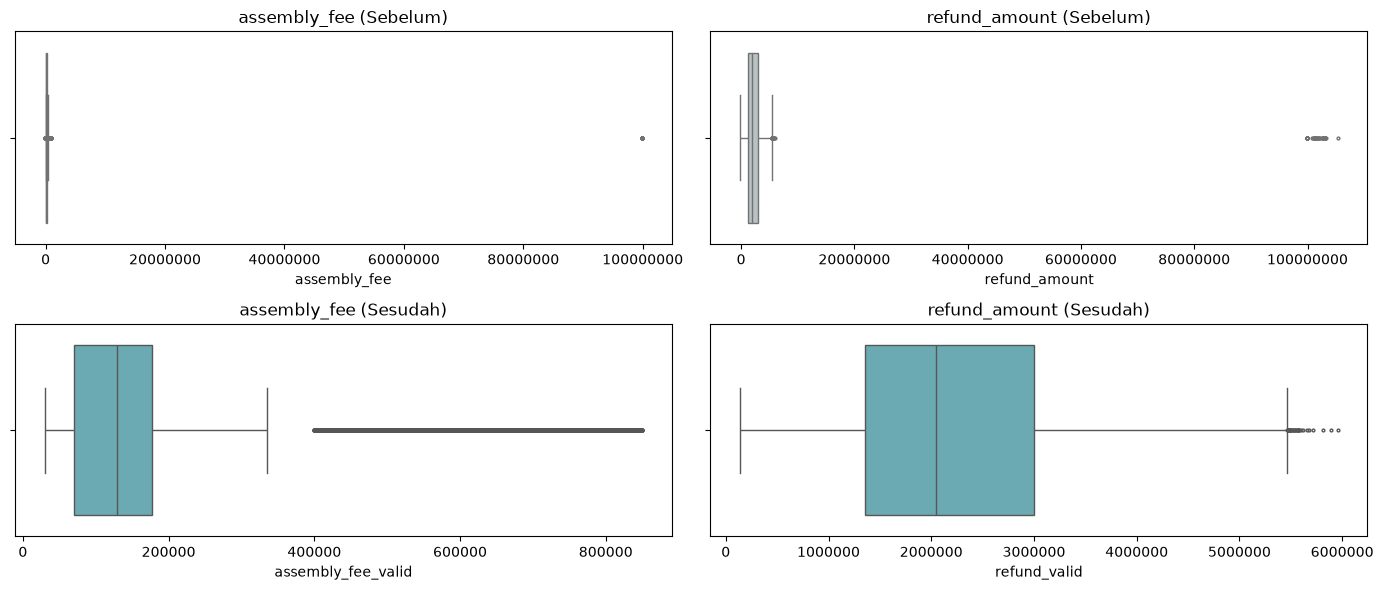

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 6))
col = [("assembly_fee", df["assembly_fee"].replace(0, np.nan), df["assembly_fee_valid"]),
            ("refund_amount", df["refund_amount"], df["refund_valid"])]
for i, (nama, sebelum, sesudah) in enumerate(col):
    for j, (r, label) in enumerate([(sebelum, "Sebelum"), (sesudah, "Sesudah")]):
        sns.boxplot(x=r.dropna(), ax=axes[j, i], color="#5FB3BF" if j else "#B8C2C5", fliersize=2)
        axes[j, i].set_title(f"{nama} ({label})")
        axes[j, i].ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

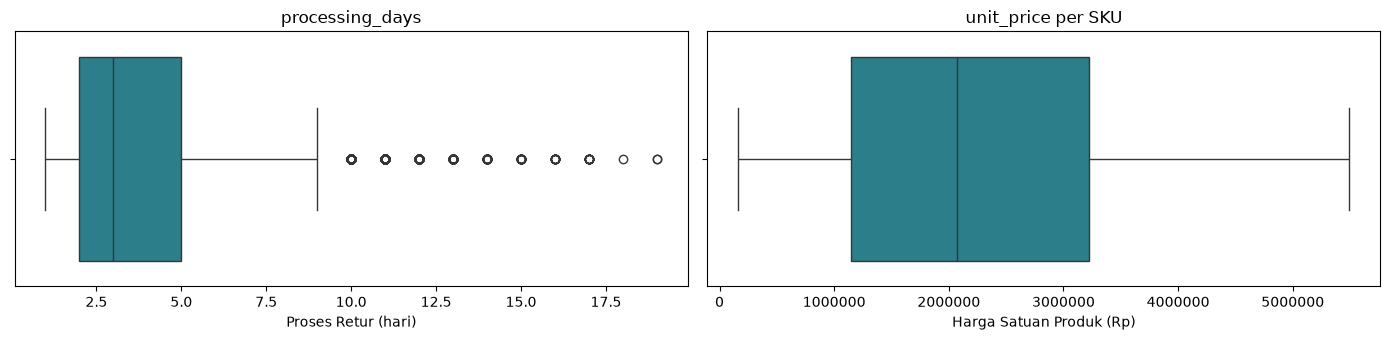

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
sns.boxplot(x=df["processing_days"].dropna(), color="#1B8A9A", ax=ax[0]); ax[0]
ax[0].set_title("processing_days")
ax[0].set_xlabel('Proses Retur (hari)')
sns.boxplot(x=df_products["unit_price"], color="#1B8A9A", ax=ax[1]); ax[1]
ax[1].set_title("unit_price per SKU")
ax[1].set_xlabel('Harga Satuan Produk (Rp)')
ax[1].ticklabel_format(style="plain", axis="x")
plt.tight_layout(); plt.show()

`processing_days` masih berada pada rentang wajar (1 - 19 hari). Nilai di atas *upper bound* adalah retur yang lambat diproses dan data ini penting untuk dianalisis kepuasan pelanggan sehingga tidak dihapus. Nilai `unit_price` juga berada pada rentang wajar (±Rp 160 ribu – Rp 5,5 juta).</p>

<a id="bab-7"></a>
# 7. ANALYTICS

<a id="bab-7-eda"></a>
## Exploratory Data Analysis

Data utama yang digunakan: **failed installation rate** = jumlah Failed ÷ (Success + Failed) dengan ketentuan orderan tersebut bersifat wajib dipasang oleh layanan Dekoruma. Order yang bersifat *No Assembly Required* dan *No Assembly Service* tidak termasuk perhitungan.

In [20]:
dipasang = df[df["installation_status"].isin(["Success", "Failed - Missing Parts", "Failed - Damaged Panel"])].copy()
dipasang["gagal"]   = dipasang["installation_status"].str.startswith("Failed").astype(int)
dipasang["missing"] = dipasang["installation_status"].eq("Failed - Missing Parts").astype(int)
dipasang["panel"]   = dipasang["installation_status"].eq("Failed - Damaged Panel").astype(int)
dipasang["bulan"]   = dipasang["order_date"].dt.month
df["bulan"]  = df["order_date"].dt.month
df["online"] = df["channel_type"].isin(["Mobile App", "Web"])
gagal = dipasang[dipasang["gagal"] == 1]
print(f"Jumlah order yang membutuhkan pemasangan oleh Dekoruma : {len(dipasang):,}")
print(f"Jumlah order yang gagal : {len(gagal):,} ({len(gagal) / len(dipasang) * 100:.1f}%)")

Jumlah order yang membutuhkan pemasangan oleh Dekoruma : 204,557
Jumlah order yang gagal : 28,782 (14.1%)


<a id="eda-1"></a>
### 1. Seberapa Besar Tingkat Kegagalan Instalasi Saat Ini?

Pertanyaan ini mengukur kondisi awal (*baseline*) yang akan dibandingkan dengan target manajemen, yaitu *failed installation* di bawah 8% dalam 6 bulan.

Failed installation rate : 14.1%  (28,782 / 204,557)
  Missing parts          : 9.08%
  Damaged panel          : 4.99%
Failed installation rate terhadap semua order  (dipasang & tidak dipasang) : 8.95%


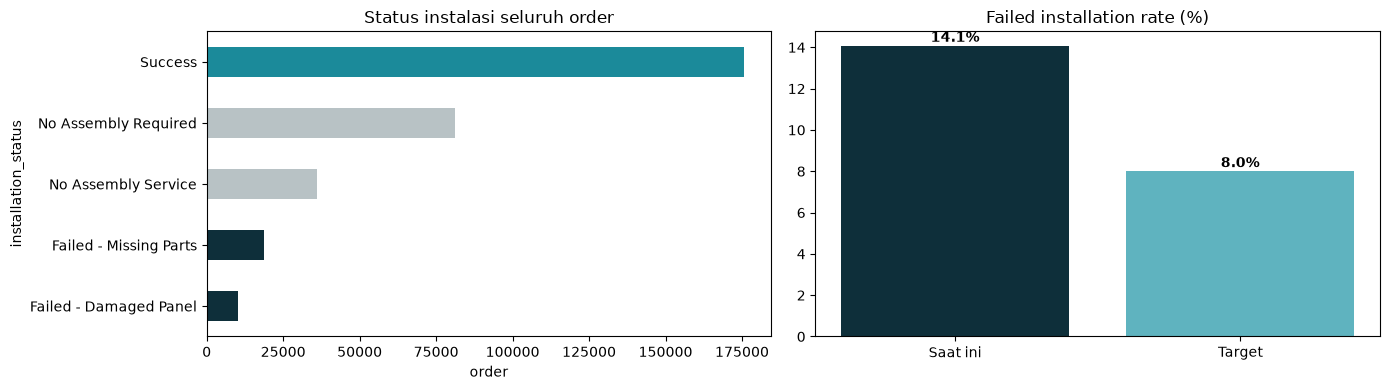

In [21]:
rate = dipasang["gagal"].mean() * 100
print(f"Failed installation rate : {rate:.1f}%  ({dipasang['gagal'].sum():,} / {len(dipasang):,})")
print(f"  Missing parts          : {dipasang['missing'].mean()*100:.2f}%")
print(f"  Damaged panel          : {dipasang['panel'].mean()*100:.2f}%")
print(f"Failed installation rate terhadap semua order  (dipasang & tidak dipasang) : {dipasang['gagal'].sum()/len(df)*100:.2f}%")

st = df["installation_status"].value_counts()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
st.plot.barh(ax=ax[0], color=[TEAL if s == "Success" else (NAVY if "Failed" in s else GRY) for s in st.index])
ax[0].invert_yaxis(); ax[0].set_title("Status instalasi seluruh order"); ax[0].set_xlabel("order")
ax[1].bar(["Saat ini", "Target"], [rate, 8], color=[NAVY, TEAL2]); ax[1].set_title("Failed installation rate (%)")
for i, v in enumerate([rate, 8]): ax[1].text(i, v + 0.2, f"{v:.1f}%", ha="center", fontweight="bold")
plt.tight_layout(); plt.show()

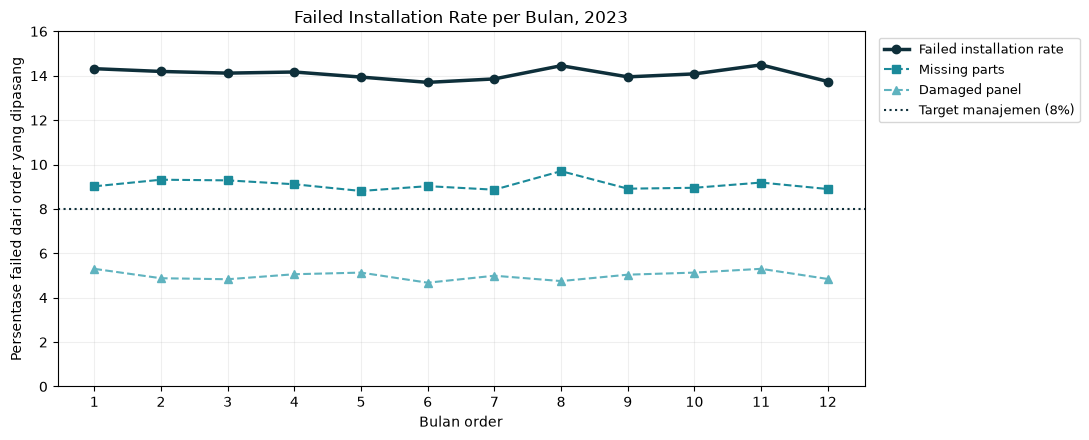

In [22]:
# failed rate bulanan dari tabel dipasang
bulanan = dipasang.groupby("bulan")[["gagal", "missing", "panel"]].mean() * 100

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(bulanan.index, bulanan["gagal"],   marker="o", lw=2.5,  color=NAVY,  label="Failed installation rate")
ax.plot(bulanan.index, bulanan["missing"], marker="s", ls="--", color=TEAL,  label="Missing parts")
ax.plot(bulanan.index, bulanan["panel"],   marker="^", ls="--", color=TEAL2, label="Damaged panel")

ax.axhline(8, color=NAVY, ls=":", lw=1.5, label="Target manajemen (8%)")

ax.set_xticks(range(1, 13))
ax.set_ylim(0, 16)
ax.set_title("Failed Installation Rate per Bulan, 2023")
ax.set_ylabel("Persentase failed dari order yang dipasang")
ax.set_xlabel("Bulan order")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout()
plt.grid(True, alpha=0.2)
plt.show()

**Insight** : Tingkat Kegagalan Instalasi Dekoruma Tahun 2023

1. `14,1% order yang membutuhkan pemasangan bersifat failed` : 28.782 dari 204.557 order.
2. `Proporsi missing parts dan damaged panel` : 9,1% gagal pemasangan karena komponen kurang dan 5,0% karena panel rusak.
3. `Gap terhadap target` : Selisih 6% terhadap target sehingga perlu penurunan hampir separuh dari kondisi sekarang untuk mencapai < 8%.

<a id="eda-2"></a>
### 2. Bagaimana Penjualan Dekoruma Sepanjang 2023 per Kanal dan Kategori?

Penjualan dihitung dari `unit_price` dengan asumsi 1 order = 1 barang dengan nilai sesuai harga katalog.

In [23]:
total_jual = df["unit_price"].sum()
print(f"Penjualan barang 2023     : Rp {(total_jual):,}")
print(f"Biaya rakit valid         : Rp {(df['assembly_fee_valid'].sum()):,}")
print(f"Refund valid : Rp{(df['refund_valid'].sum()):,} ({df['refund_valid'].sum()/total_jual*100:.1f}% dari penjualan)")

column = df.groupby("channel_type")["unit_price"].agg(order="size", penjualan="sum")
column["persen"] = column["penjualan"] / total_jual * 100
cat = df.groupby("category")["unit_price"].agg(order="size", penjualan="sum").sort_values("penjualan", ascending=False)
cat["persen"] = cat["penjualan"] / total_jual * 100
display(column, cat)

Penjualan barang 2023     : Rp 702,149,585,145
Biaya rakit valid         : Rp 27,612,551,057.0
Refund valid : Rp42,031,741,600.0 (6.0% dari penjualan)


,order,penjualan,persen
channel_type,,,
Mobile App,20986,45843779427,6.529062
Physical Store,280001,611414407632,87.077515
Web,20773,44891398086,6.393424


,order,penjualan,persen
category,,,
Sofa,63144,226330132112,32.233891
Lemari,74885,213323104491,30.381433
Meja Makan,49927,85337445430,12.153741
Kursi Kerja,71062,79199931349,11.279638
Bed,16875,74761501622,10.647518
Dekorasi,45867,23197470141,3.303779


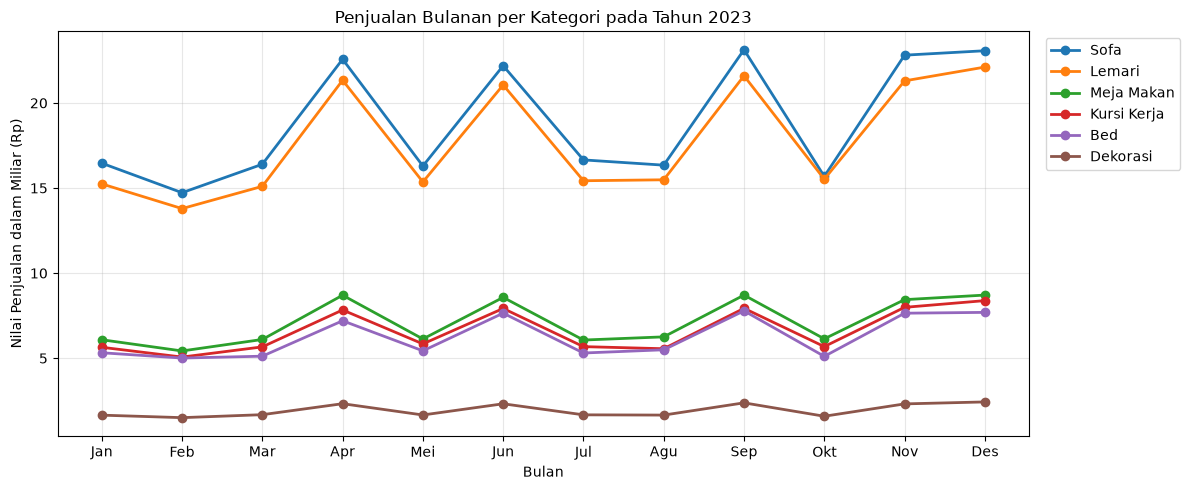

In [24]:
tren = df.pivot_table(index="bulan", columns="category", values="unit_price", aggfunc="sum") / 1e9
tren = tren[tren.sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12, 5))
tren.plot(ax=ax, marker="o", linewidth=2)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"])
ax.set(xlabel="", ylabel="Rp miliar", title="Penjualan Bulanan per Kategori pada Tahun 2023")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.ylabel('Nilai Penjualan dalam Miliar (Rp)')
plt.xlabel('Bulan')
plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

**Insight** : Penjualan Dekoruma 2023

1. `Total penjualan barang ±Rp 702,1 miliar` dari 321.760 order (rata-rata ±Rp 2,18 juta per order). Setelah dikurangi refund valid Rp 42,0 miliar, penjualan bersih ±Rp 660,1 miliar.
2. `Toko fisik (DEC)` mendominasi 87,1% penjualan, sedangkan Mobile App dan Web masing-masing hanya ±6,5%.
3. `Sofa dan Lemari` adalah kategori yang menyumbang penjualan terbesar (Sofa 32.2% dan Lemari 30.4%).

<a id="eda-3"></a>
### 3. Bagaimana Tren Kegagalan Instalasi per Kategori Sepanjang 2023?

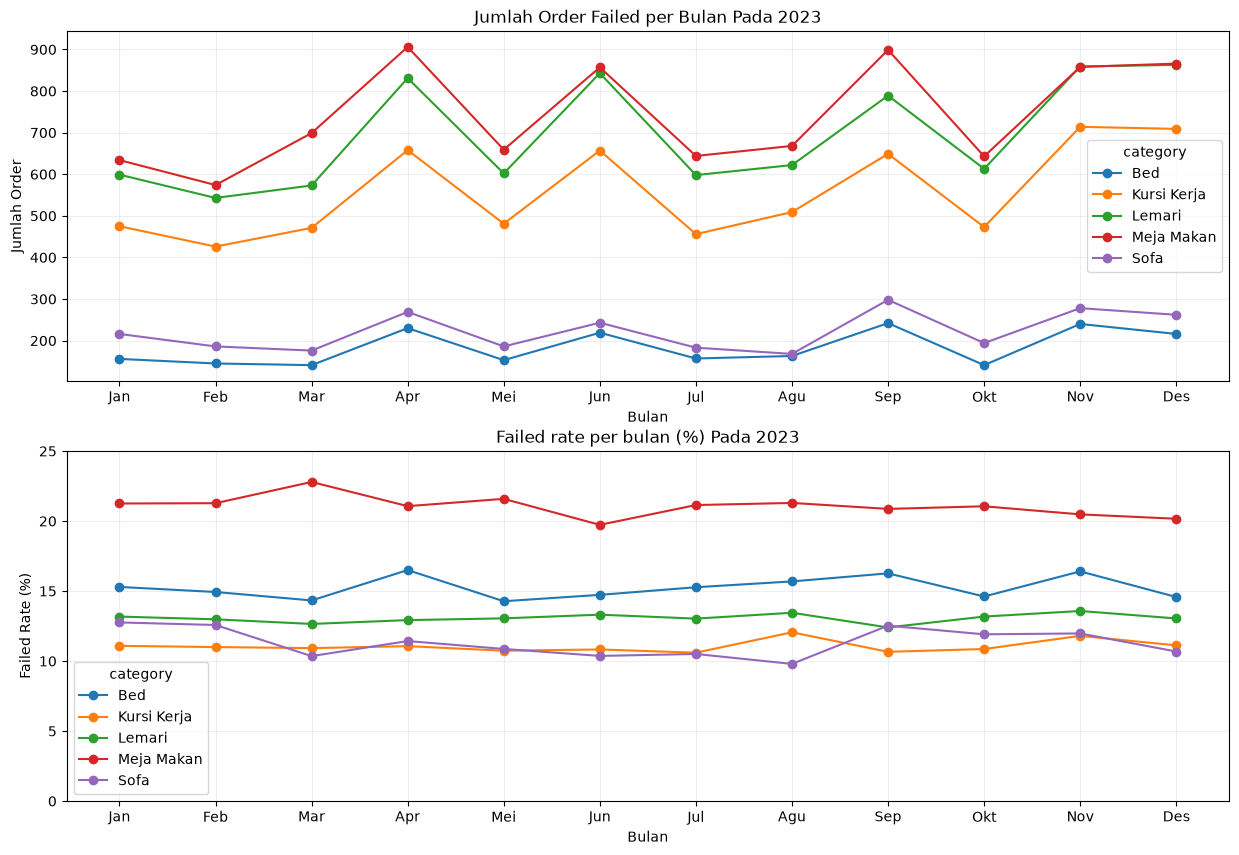

,total_failed,failed_rate,rate_min_bulanan,rate_max_bulanan
category,,,,
Meja Makan,8907,21.0,19.7,22.8
Bed,2203,15.3,14.3,16.5
Lemari,8335,13.1,12.4,13.6
Sofa,2659,11.3,9.8,12.8
Kursi Kerja,6678,11.1,10.6,12.1


In [25]:
jumlah_gagal = dipasang.pivot_table(index="bulan", columns="category", values="gagal", aggfunc="sum")
rate_gagal = dipasang.pivot_table(index="bulan", columns="category", values="gagal", aggfunc="mean") * 100

fig, ax = plt.subplots(2, 1, figsize=(15, 10))
jumlah_gagal.plot(ax=ax[0], marker="o"); ax[0].set(title="Jumlah Order Failed per Bulan Pada 2023", ylabel="order")
rate_gagal.plot(ax=ax[1], marker="o"); ax[1].set(title="Failed rate per bulan (%) Pada 2023", ylim=(0, 25))
for a in ax:
    a.set_xticks(range(1, 13))
    a.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"])
    a.set_xlabel("")
ax[0].grid(True, alpha=0.2)
ax[0].set_ylabel('Jumlah Order')
ax[0].set_xlabel('Bulan')
ax[1].set_ylabel('Failed Rate (%)')
ax[1].set_xlabel('Bulan')
ax[1].grid(True, alpha=0.2)
plt.show()

ringkas = dipasang.groupby("category")["gagal"].agg(total_failed="sum", failed_rate="mean")
ringkas["failed_rate"] *= 100
ringkas["rate_min_bulanan"] = rate_gagal.min(); ringkas["rate_max_bulanan"] = rate_gagal.max()
ringkas.sort_values("failed_rate", ascending=False).round(1)

**Insight** : Tren Kegagalan per Kategori

1. `Jumlah order yang gagal naik-turun mengikuti penjualan` : lonjakan pada April, Juni, September, November, dan Desember terjadi karena volume order lebih banyak.
2. `Failed rate stabil sepanjang tahun` : setiap kategori memiliki tingkat kegagalan yang cenderung stabil sepanjang tahun 2023.
3. `Failed rate pada Meja Makan selalu paling tinggi` sepanjang tahun 2023 (21%), lalu failed rate tertinggi kedua ada pada kategori Bed (±15%), Lemari (±13%), Sofa dan Kursi Kerja (±11%). Sedangkan dekorasi tidak muncul karena produknya tidak perlu instalasi.

<a id="eda-4"></a>
### 4. Berapa Nilai Refund Akibat Kegagalan Instalasi per Kategori dan Bobot?

In [26]:
total_valid = df["refund_valid"].sum()
gr = gagal[gagal["refund_valid"].notna()]
print(f"Total klaim refund valid       : Rp {total_valid:,.0f}")
print(f"  dari order gagal instalasi   : Rp {gr['refund_valid'].sum():,.0f} ({gr['refund_valid'].sum()/total_valid*100:.1f}%)")
print(f"  jumlah klaim gagal instalasi : {len(gr):,}")

df["refund_failed"] = df["refund_valid"].where(df["installation_status"].str.startswith("Failed", na=False)).fillna(0)
seg = df.groupby(["category", "weight_category"]).agg(penjualan=("unit_price", "sum"), refund_failed=("refund_failed", "sum"))
seg["persen_refund"] = seg["refund_failed"] / seg["penjualan"] * 100
seg.style.format({"penjualan": "Rp {:,.0f}", "refund_failed": "Rp {:,.0f}", "persen_refund": "{:.2f}%"})

Total klaim refund valid       : Rp 42,031,741,600
  dari order gagal instalasi   : Rp 38,544,602,100 (91.7%)
  jumlah klaim gagal instalasi : 17,092


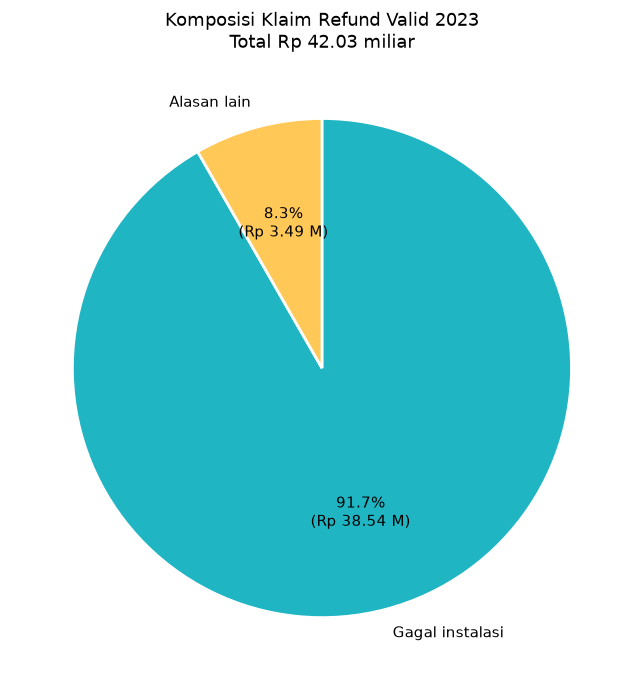

In [27]:
refund_gagal = gr["refund_valid"].sum()
refund_lain  = total_valid - refund_gagal

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie([refund_gagal, refund_lain],
       labels=["Gagal instalasi", "Alasan lain"],
       colors=["#1FB5C2", "#FFC857"],
       autopct=lambda p: f"{p:.1f}%\n(Rp {p * total_valid / 100 / 1e9:.2f} M)",
       startangle=90,
       counterclock=False,
       wedgeprops={"edgecolor": "white", "linewidth": 2},
       textprops={"fontsize": 11})
ax.set_title(f"Komposisi Klaim Refund Valid 2023\nTotal Rp {total_valid/1e9:.2f} miliar", fontsize=13)
plt.tight_layout(); plt.show()

**Insight** : Nilai Refund Gagal Instalasi

1. `Rp 38,54 miliar (91,7%)` dari seluruh klaim refund valid (Rp 42,03 miliar) berasal dari order gagal instalasi.
2. `Lemari` menyumbang rupiah terbesar (±Rp 13,8 miliar), sedangkan bobot `Bulky dan Oversized` menyumbang ±75% nilai klaim.
3. `Proporsi Refund Meja Makan` : sekitar 10,4% dari penjualan Meja Makan menjadi nilai refund gagal instalasi.
4. `Rasio` antar bobot dalam satu kategori hampir sama : masalahnya ada pada kategori, bukan pada berat barangnya.

<a id="eda-5"></a>
### 5. Bagaimana Klaim Refund Diselesaikan?

,klaim,nilai,avg_satisfaction_score,persentase
refund_method,,,,
Refund ke Rekening,8839,"19,778,070,900.00",4.09,47.06
Tukar Barang,6529,"14,669,439,900.00",3.50,34.90
Store Credit,3491,"7,584,230,800.00",3.51,18.04


,klaim,nilai
return_reason,,
Failed Installation - Missing Parts,9988,"22,490,580,700.00"
Failed Installation - Damaged Panel,7104,"16,054,021,400.00"
Barang Tidak Sesuai Pesanan,707,"1,385,363,700.00"
Berubah Pikiran (Change of Mind),608,"1,203,564,700.00"
Kualitas Tidak Sesuai Ekspektasi,452,"898,211,100.00"


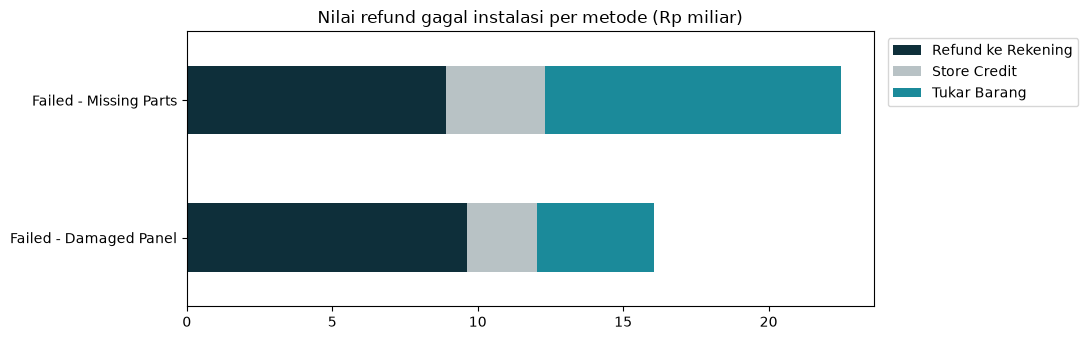

refund_method,Refund ke Rekening,Store Credit,Tukar Barang
installation_status,,,
Failed - Damaged Panel,60.10,15.00,24.90
Failed - Missing Parts,39.60,15.10,45.30


In [28]:
# dari semua klaim refund
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

valid = df[df["refund_valid"].notna()]
metode = valid.groupby("refund_method").agg(klaim=("refund_valid", "size"), nilai=("refund_valid", "sum"),
                                            avg_satisfaction_score=("satisfaction_score", "mean"))
metode["persentase"] = metode["nilai"] / metode["nilai"].sum() * 100
display(metode.sort_values("nilai", ascending=False))

alasan = valid.groupby("return_reason").agg(klaim=("refund_valid", "size"), nilai=("refund_valid", "sum")).sort_values("nilai", ascending=False)
display(alasan)

pm = gr.pivot_table(index="installation_status", columns="refund_method", values="refund_valid", aggfunc="sum") / 1e9
pm.plot.barh(stacked=True, color=["#0E2F3A", "#B8C2C5", "#1B8A9A"], figsize=(11, 3.5))
plt.title("Nilai refund gagal instalasi per metode (Rp miliar)"); plt.ylabel(""); plt.legend(bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()
(pm.div(pm.sum(axis=1), axis=0) * 100).round(1)

**Insight** : Metode Penyelesaian Refund

1. `Sejumlah ±Rp 18,6 miliar yang ditransfer ke rekening customer` dari Rp 38,5 miliar klaim gagal instalasi, sedangkan sisanya berupa tukar barang atau menjadi store credit.
2. `Missing parts paling banyak diselesaikan dengan tukar barang (±45%)`, sedangkan `panel rusak paling banyak di-refund ke rekening (±60%)`.
3. `Customer yang menerima transfer paling puas` (skor kepuasan ±4,09) dibanding tukar barang dan store credit (±3,5).

<a id="eda-6"></a>
### 6. Supplier Mana yang Paling Mendorong Kegagalan Instalasi?

In [29]:
sup = dipasang.groupby("supplier_name").agg(order=("gagal", "size"), gagal=("gagal", "sum"), rate=("gagal", "mean"),
                                            missing=("missing", "mean"), panel=("panel", "mean"))
sup[["rate", "missing", "panel"]] *= 100
sup = sup[sup["order"] >= 300].sort_values("rate", ascending=False)
sup.head(10).round(2)

,order,gagal,rate,missing,panel
supplier_name,,,,,
UMKM Furnitur Ciputat,11657,4297,36.86,31.79,5.07
Mebel Rakyat Klaten,12564,4505,35.86,30.95,4.91
Perajin Mebel Yogya,5413,636,11.75,6.76,4.99
Bengkel Kayu Pak Slamet,6107,704,11.53,6.35,5.17
Perajin Kayu Solo,10874,1249,11.49,6.15,5.33
Karya Perajin Jepara,10064,1149,11.42,6.21,5.21
Perajin Rotan Cirebon,7204,817,11.34,6.15,5.19
Mega Furnitur Industri,353,40,11.33,6.23,5.10
Sumber Kayu Jaya,21773,2445,11.23,6.25,4.98


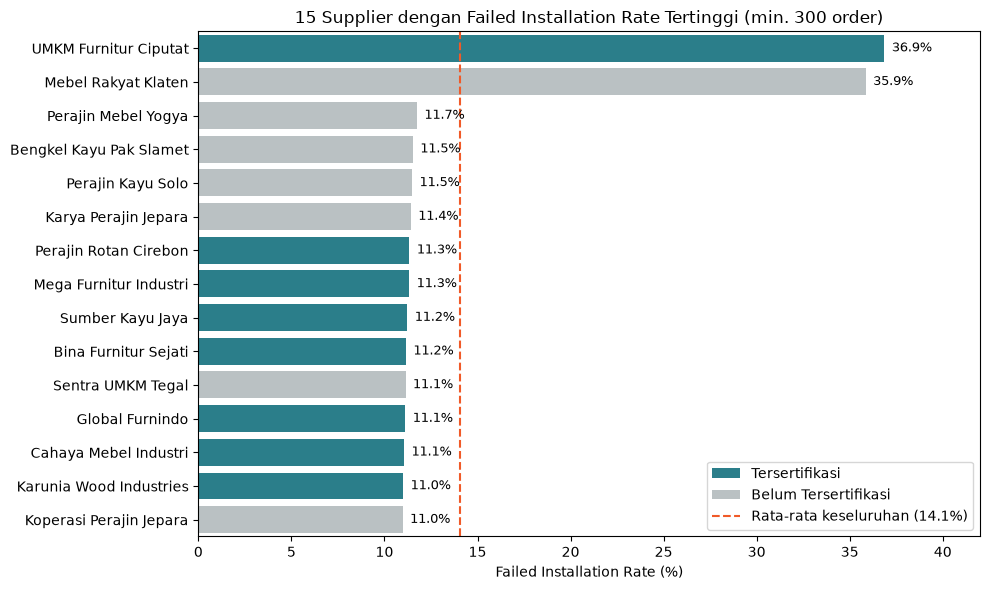

In [38]:
# failed rate keseluruhan (order yang dirakit tim Dekoruma)
rate_total = dipasang["gagal"].mean() * 100

# mengkategorikan supplier berdasarkan status sertifikasinya
sertifikasi = df_suppliers.drop_duplicates("supplier_name").set_index("supplier_name")["quality_certification_status"]
top15 = sup.head(15).join(sertifikasi).reset_index()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top15, y="supplier_name", x="rate", hue="quality_certification_status",
            dodge=False, palette={"Tersertifikasi": "#1B8A9A", "Belum Tersertifikasi": "#B8C2C5"}, ax=ax)
ax.axvline(rate_total, color="#F05A28", ls="--", lw=1.5, label=f"Rata-rata keseluruhan ({rate_total:.1f}%)")

for i, v in enumerate(top15["rate"]):
    ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=9)

ax.set_title("15 Supplier dengan Failed Installation Rate Tertinggi (min. 300 order)")
ax.set_xlabel("Failed Installation Rate (%)")
ax.set_ylabel("")
ax.set_xlim(0, 42)
ax.legend(title="", loc="lower right")
plt.tight_layout()
plt.show()

In [30]:
top2 = sup.index[:2].tolist()
dipasang["supplier_buruk"] = dipasang["supplier_name"].isin(top2).astype(int)
B, OK = dipasang[dipasang["supplier_buruk"] == 1], dipasang[dipasang["supplier_buruk"] == 0]
print("Dua supplier teratas:", top2)
print(f"Porsi order dua supplier teratas   : {dipasang['supplier_buruk'].mean()*100:.1f}%")
print(f"Porsi gagal dua supplier teratas  : {dipasang.loc[dipasang['gagal']==1, 'supplier_buruk'].mean()*100:.1f}%")
print(f"Porsi missing dua supplier teratas : {dipasang.loc[dipasang['missing']==1, 'supplier_buruk'].mean()*100:.1f}%")
print(f"Failed rate dua supplier teratas  : {B['gagal'].mean()*100:.1f}% vs {OK['gagal'].mean()*100:.1f}% supplier lain")
print(f"  missing     : {B['missing'].mean()*100:.1f}% vs {OK['missing'].mean()*100:.1f}%")
print(f"  panel       : {B['panel'].mean()*100:.1f}% vs {OK['panel'].mean()*100:.1f}%")

# skenario: failed rate dua supplier disamakan dengan rata-rata supplier lain
hindar = B["gagal"].sum() - len(B) * OK["gagal"].mean()
p_ref = B.loc[B["gagal"] == 1, "refund_valid"].notna().mean()
avg_ref = B.loc[(B["gagal"] == 1) & B["refund_valid"].notna(), "refund_valid"].mean()
print(f"\nSkenario failed rate nasional : {(dipasang['gagal'].sum() - hindar)/len(dipasang)*100:.1f}%")
print(f"Kegagalan terhindar           : {hindar:,.0f} order")
print(f"Estimasi klaim terhindar      : Rp {hindar * p_ref * avg_ref:,.0f} (perkiraan)")

Dua supplier teratas: ['UMKM Furnitur Ciputat', 'Mebel Rakyat Klaten']
Porsi order dua supplier teratas   : 11.8%
Porsi gagal dua supplier teratas  : 30.6%
Porsi missing dua supplier teratas : 40.9%
Failed rate dua supplier teratas  : 36.3% vs 11.1% supplier lain
  missing     : 31.4% vs 6.1%
  panel       : 5.0% vs 5.0%

Skenario failed rate nasional : 11.1%
Kegagalan terhindar           : 6,118 order
Estimasi klaim terhindar      : Rp 7,601,978,502 (perkiraan)


In [31]:
stat = dipasang.groupby("supplier_id").agg(order_terpasang=("gagal", "size"), order_gagal=("gagal", "sum"))

kolom = ["supplier_name", "supplier_type", "region", "primary_family",
         "secondary_family", "quality_certification_status"]
semua = df_suppliers.set_index("supplier_id")[kolom].join(stat).fillna({"order_terpasang": 0, "order_gagal": 0})
semua["failed_rate"] = (semua["order_gagal"] / semua["order_terpasang"] * 100).round(1)
semua = semua.sort_values("order_terpasang", ascending=False)

display(semua.head(7))

,supplier_name,supplier_type,region,primary_family,secondary_family,quality_certification_status,order_terpasang,order_gagal,failed_rate
supplier_id,,,,,,,,,
SUP-PBR-BKS-05,Sumber Kayu Jaya,Pabrik,Bekasi,Kursi,Meja,Tersertifikasi,"21,773.00","2,445.00",11.20
SUP-PBR-SDA-03,Karunia Wood Industries,Pabrik,Sidoarjo,Kursi,Lemari,Tersertifikasi,"20,285.00","2,233.00",11.00
SUP-PBR-SDA-02,Sinar Mebel Nusantara,Pabrik,Sidoarjo,Kursi,NaN,Tersertifikasi,"18,906.00","2,036.00",10.80
SUP-PRJ-KLT-05,Mebel Rakyat Klaten,Perajin Lokal,Klaten,Meja,Lemari,Belum Tersertifikasi,"12,564.00","4,505.00",35.90
SUP-PRJ-KLT-04,UMKM Furnitur Ciputat,Perajin Lokal,Klaten,Meja,Bed,Tersertifikasi,"11,657.00","4,297.00",36.90
SUP-PRJ-KLT-02,Perajin Kayu Solo,Perajin Lokal,Klaten,Sofa,Lemari,Belum Tersertifikasi,"10,874.00","1,249.00",11.50
SUP-PRJ-CRB-04,Sentra UMKM Tegal,Perajin Lokal,Cirebon,Sofa,Meja,Belum Tersertifikasi,"8,121.00",904.00,11.10


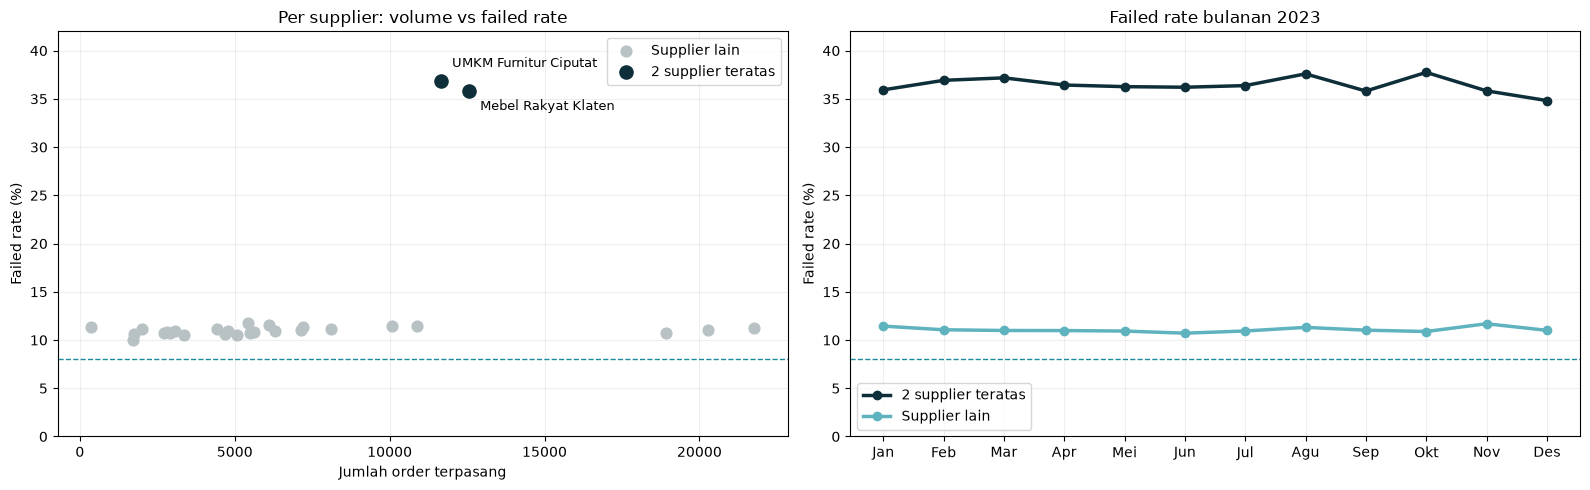

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
s = sup.copy()
buruk = s.index.isin(top2)
ax[0].scatter(s.loc[~buruk, "order"], s.loc[~buruk, "rate"], s=60, color=GRY, label="Supplier lain")
ax[0].scatter(s.loc[buruk, "order"], s.loc[buruk, "rate"], s=90, color=NAVY, label="2 supplier teratas")
for (n, r), dy in zip(s[buruk].iterrows(), [10, -14]):
    ax[0].annotate(n, (r["order"], r["rate"]), xytext=(8, dy), textcoords="offset points", fontsize=9)
ax[0].axhline(8, color=TEAL, ls="--", lw=1)
ax[0].set(xlabel="Jumlah order terpasang", ylabel="Failed rate (%)", ylim=(0, 42), title="Per supplier: volume vs failed rate")
ax[0].legend()
ax[0].grid(True, alpha=0.2)

tb = B.groupby("bulan")["gagal"].mean() * 100
to = OK.groupby("bulan")["gagal"].mean() * 100
ax[1].plot(tb.index, tb.values, marker="o", color=NAVY, lw=2.5, label="2 supplier teratas")
ax[1].plot(to.index, to.values, marker="o", color=TEAL2, lw=2.5, label="Supplier lain")
ax[1].axhline(8, color=TEAL, ls="--", lw=1)
ax[1].set_xticks(range(1, 13))
ax[1].set_xticklabels(["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"])
ax[1].set(ylim=(0, 42), ylabel="Failed rate (%)", title="Failed rate bulanan 2023"); ax[1].legend()
ax[1].grid(True, alpha=0.2)
plt.tight_layout(); plt.show()

**Insight** : Supplier Penyebab Kegagalan

1. `Dua supplier` memiliki tingkat kegagalan 36–37% atau sebesar 3 kali lipat dari 30 supplier lain yang memiliki tingkat kegagalan ±11%. Keduanya supplier tersebut hanya memegang 11,8% order terpasang, tetapi menyumbang 30,6% dari seluruh kegagalan pemasangan.
2. `Penyebab kegagalan paling besar adalah missing parts` jika dibandingkan dengan, sedangkan panel rusak sama (±5%). Masalah dua supplier ini adalah kelengkapan komponen.
3. `Konsisten sepanjang 2023` : tidak ada tren naik atau turun pada failed rate 2 supplier teratas.
4. `Skenario perbaikan` : jika keduanya setara supplier lain (failed rate nasional) turun ke ±11,1%, klaim yang dapat dihindari diperkirakan bisa mencapai ±Rp 7,6 miliar. Angka ini adalah estimasi dan belum cukup untuk target perusahaan < 8% failed rate.

<a id="eda-7"></a>
### 7. Apakah Kategori, Sertifikasi, Toko, atau Wilayah Ikut Berpengaruh?

In [33]:
kat_cmp = pd.DataFrame({"rate_semua_supplier": dipasang.groupby("category")["gagal"].mean() * 100,
                        "rate_tanpa_2_supplier": OK.groupby("category")["gagal"].mean() * 100}).round(1)
sert = dipasang.groupby("quality_certification_status")["gagal"].agg(jumlah_order="size", rate="mean")
sert["rate"] *= 100
display(kat_cmp, sert.round(1))

x = df.dropna(subset=["supplier_id"])   # seluruh orderan
print(f"Supplier per toko : {x.groupby('store_id')['supplier_id'].nunique().min()}–{x.groupby('store_id')['supplier_id'].nunique().max()}")
print(f"Toko per supplier : {x.groupby('supplier_id')['store_id'].nunique().min()}–{x.groupby('supplier_id')['store_id'].nunique().max()}")

,rate_semua_supplier,rate_tanpa_2_supplier
category,,
Bed,15.30,11.00
Kursi Kerja,11.10,11.10
Lemari,13.10,11.10
Meja Makan,21.00,11.00
Sofa,11.30,11.30


,jumlah_order,rate
quality_certification_status,,
Belum Tersertifikasi,83670,14.90
Tersertifikasi,113529,13.60


Supplier per toko : 32–32
Toko per supplier : 40–40


In [34]:
# Menggunakan data yang orderannya membutuhkan pemasangan oleh Dekoruma

# Failed rate per kanal
per_kanal = (dipasang.groupby("channel_type")["gagal"]
               .agg(jumlah_order="size", order_gagal="sum", failed_rate="mean")
               .sort_values("order_gagal", ascending=False))
per_kanal["failed_rate"] = (per_kanal["failed_rate"] * 100).round(2)
display(per_kanal)
 
# Failed rate hanya dari toko fisik dan kota customer diketahui
fs = dipasang[dipasang["channel_type"] == "Physical Store"].dropna(subset=["city", "domicile_city"]).copy()
fs["sekota"] = fs["city"].eq(fs["domicile_city"])

ringkas_sekota = (fs.groupby("sekota")["gagal"]
                    .agg(jumlah_order="size", order_gagal="sum", failed_rate="mean")
                    .rename(index={True: "Sekota dengan customer", False: "Beda kota"})
                    .sort_values("order_gagal", ascending=False))
ringkas_sekota["failed_rate"] = (ringkas_sekota["failed_rate"] * 100).round(2)
ringkas_sekota["persen_order_gagal"] = (ringkas_sekota["order_gagal"] / ringkas_sekota["order_gagal"].sum() * 100).round(1)
display(ringkas_sekota)
 
 
# Failed rate per kota yang memiliki DEC
per_toko = (fs.groupby("city")
              .agg(jumlah_order=("gagal", "size"), order_gagal=("gagal", "sum"), failed_rate=("gagal", "mean"))
              .sort_values("order_gagal", ascending=False))
per_toko["failed_rate"] = (per_toko["failed_rate"] * 100).round(1)
per_toko["persen_sekota_gagal"] = (fs[fs["gagal"] == 1].groupby("city")["sekota"].mean() * 100).round(1)
display(per_toko)
 
 
# Failed rate dengan kota yang sama vs beda kota
fs = dipasang[dipasang["channel_type"] == "Physical Store"].dropna(subset=["city", "domicile_city"]).copy()
fs["sekota"] = fs["city"].eq(fs["domicile_city"])
 
banding_sekota = (fs.groupby("sekota")["gagal"]
                    .agg(jumlah_order="size", order_gagal="sum", failed_rate="mean")
                    .rename(index={True: "Sekota", False: "Beda kota"}))
banding_sekota["failed_rate"] = (banding_sekota["failed_rate"] * 100).round(2)
display(banding_sekota)

,jumlah_order,order_gagal,failed_rate
channel_type,,,
Physical Store,178129,25088,14.08
Mobile App,13229,1878,14.20
Web,13199,1816,13.76


,jumlah_order,order_gagal,failed_rate,persen_order_gagal
sekota,,,,
Sekota dengan customer,102723,14511,14.13,60.60
Beda kota,67416,9421,13.97,39.40


,jumlah_order,order_gagal,failed_rate,persen_sekota_gagal
city,,,,
Alam Sutera,41751,5873,14.10,61.00
Kelapa Gading,36797,5152,14.00,59.70
Bintaro,26217,3717,14.20,60.40
Kemang,20860,2984,14.30,62.20
Bekasi,21005,2897,13.80,61.00
Surabaya,11818,1626,13.80,60.20
Medan,6983,1024,14.70,60.00
Bandung,4708,659,14.00,59.30


,jumlah_order,order_gagal,failed_rate
sekota,,,
Beda kota,67416,9421,13.97
Sekota,102723,14511,14.13


In [35]:
# Data terfokus pada 2 supplier dengan failed rate tertinggi
wilayah = {"Jabodetabek": ["Jakarta/Priok", "Bekasi", "Tangerang", "Depok", "Bintaro", "Alam Sutera", "Kelapa Gading", "Kemang"],
           "Jawa Barat": ["Bandung", "Cirebon"],
           "Jateng-DIY": ["Semarang", "Solo", "Klaten", "Jepara", "Tegal", "Yogyakarta"],
           "Jawa Timur": ["Surabaya", "Surabaya/Perak", "Sidoarjo", "Malang"]}
ke_wil = {kota: w for w, daftar in wilayah.items() for kota in daftar}

w = B.dropna(subset=["domicile_city"]).copy()
w["wil_supplier"] = w["region"].map(ke_wil)
w["wil_customer"] = w["domicile_city"].map(ke_wil).fillna("Luar Jawa / lainnya")
w["satu_wilayah"] = w["wil_supplier"].eq(w["wil_customer"])

# tabel per wilayah customer
per_wilayah = (w.groupby("wil_customer")["gagal"]
                .agg(jumlah_order="size", order_gagal="sum", failed_rate="mean")
                .sort_values("order_gagal", ascending=False))
per_wilayah["failed_rate"] = (per_wilayah["failed_rate"] * 100).round(1)
display(per_wilayah)

print(f"Persentase order gagal yang customernya satu wilayah dengan supplier: {w.loc[w['gagal']==1, 'satu_wilayah'].mean()*100:.1f}%")

# tabel satu wilayah vs beda wilayah antara customer dan supplier
banding = (w.groupby("satu_wilayah")["gagal"]
             .agg(jumlah_order="size", order_gagal="sum", failed_rate="mean")
             .rename(index={True: "Satu wilayah", False: "Beda wilayah"}))
banding["failed_rate"] = (banding["failed_rate"] * 100).round(1)
display(banding)

,jumlah_order,order_gagal,failed_rate
wil_customer,,,
Jabodetabek,15330,5536,36.10
Luar Jawa / lainnya,3438,1250,36.40
Jawa Timur,2116,819,38.70
Jawa Barat,1307,455,34.80
Jateng-DIY,1043,364,34.90


Persentase order gagal yang customernya satu wilayah dengan supplier: 4.3%


,jumlah_order,order_gagal,failed_rate
satu_wilayah,,,
Beda wilayah,22191,8060,36.30
Satu wilayah,1043,364,34.90


In [ ]:
# Menggunakan data orderan yang membutuhkan pemasangan oleh Dekoruma

# hubungan pemasangan dengan tim instalasi
hub_kota = {"JKT": ["Alam Sutera", "Bekasi", "Bintaro", "Kelapa Gading", "Kemang", "Depok", "Tangerang"],
            "BDG": ["Bandung"],
            "MDN": ["Medan"],
            "SBY": ["Surabaya"]}
kota_ke_hub = {kota: hub for hub, daftar in hub_kota.items() for kota in daftar}

# order online dengan kota customer diketahui
online = dipasang[dipasang["channel_type"].isin(["Mobile App", "Web"])].dropna(subset=["domicile_city"]).copy()
online["hub_tukang"] = online["installer_id"].str.split("-").str[1]
online["hub_customer"] = online["domicile_city"].map(kota_ke_hub)      # kota tanpa DEC -> NaN
online["satu_daerah"] = online["hub_tukang"].eq(online["hub_customer"])

tim_daerah = (online.groupby("satu_daerah")["gagal"]
                .agg(jumlah_order="size", order_gagal="sum", failed_rate="mean")
                .rename(index={True: "Tim satu daerah dengan customer",
                               False: "Tim beda daerah (kota tanpa DEC, dilayani oleh tukang -JKT)"})
                .sort_values("jumlah_order", ascending=False))
tim_daerah["failed_rate"] = (tim_daerah["failed_rate"] * 100).round(1)
display(tim_daerah)

# tabel domisili customer dan tukang yang memasang
display(pd.crosstab(online["domicile_city"], online["hub_tukang"]))

,jumlah_order,order_gagal,failed_rate
satu_daerah,,,
Tim satu daerah dengan customer,23874,3337,14.00
"Tim beda daerah (kota tanpa DEC, dilayani oleh tukang -JKT)",1994,274,13.70


hub_tukang,BDG,JKT,MDN,SBY
domicile_city,,,,
Alam Sutera,0,2959,0,0
Balikpapan,0,209,0,0
Bandung,2963,0,0,0
Bekasi,0,2916,0,0
Bintaro,0,2941,0,0
Denpasar,0,177,0,0
Depok,0,176,0,0
Kelapa Gading,0,2981,0,0
Kemang,0,2904,0,0


**Insight** : Faktor Bermasalah adalah Supplier

1. `Faktor bermasalah adalah supplier` : setelah dua supplier dikeluarkan, failed rate semua kategori konvergen ke ±11% (Meja Makan 21,0% → 11,0%).
2. `Sertifikasi` berpengaruh sedikit (13,6% vs 14,9%) sehingga sertifikasi belum menjamin kelengkapan komponen.
3. `Semua supplier memasok ke semua toko` (32 supplier menyalurkan barang ke 40 toko), sehingga masalah tidak dapat dilacak melalui toko.
4. `Jarak bukan penyebab` : kedua supplier tercatat berregion Klaten, dan hanya ±4% order gagal mereka dikirim ke customer di wilayah yang sama.

<a id="eda-8"></a>
### 8. Apakah Jeda Pengiriman ke Instalasi Memengaruhi Kegagalan?

Pada bagian ini menguji apakah jeda yang lebih lama akan mempengaruhi tingkat kegagalan.

,order,gagal,rate
jeda_instalasi,,,
0.00,26249,3783,14.41
1.00,30964,4433,14.32
2.00,41913,6081,14.51
3.00,42133,6176,14.66
4.00,31178,4454,14.29
5.00,17050,2473,14.50
6.00,9484,1382,14.57


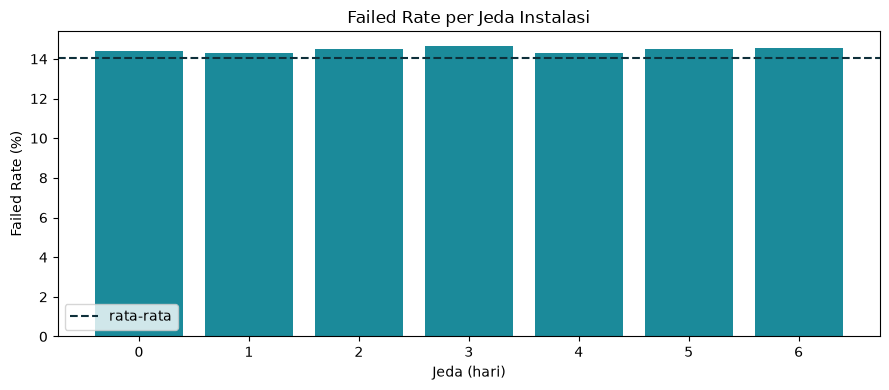

In [42]:
dj = dipasang.dropna(subset=["jeda_instalasi"])
jr = dj.groupby("jeda_instalasi")["gagal"].agg(order="size", gagal="sum", rate="mean")
jr["rate"] *= 100
display(jr.round(2))

plt.figure(figsize=(9, 4))
plt.bar(jr.index.astype(int).astype(str), jr["rate"], color=TEAL)
plt.axhline(dipasang["gagal"].mean() * 100, color=NAVY, ls="--", label="rata-rata")
plt.xlabel("Jeda (hari)"); plt.ylabel("Failed Rate (%)"); plt.title("Failed Rate per Jeda Instalasi"); plt.legend()
plt.tight_layout(); plt.show()

**Insight** : Jeda Pengiriman dengan Instalasi

1. `Failed rate relatif sama pada semua jeda` (failed rate bernilai ±14,3%–14,7% untuk jeda 0–6 hari).
2. `Pemasangan ≤ 24 jam belum terbukti` menurunkan kegagalan pada data ini.

<a id="eda-9"></a>
### 9. Apakah Kerusakan Panel Terkonsentrasi pada Faktor Tertentu?

In [46]:
hasil = []
for col, nama in [("category", "Kategori"), ("weight_category", "Bobot"), ("store_tier", "Tier toko"),
                  ("supplier_type", "Tipe supplier"), ("quality_certification_status", "Sertifikasi")]:
    g = dipasang.groupby(col)["panel"].agg(jumlah_order="size", panel_rusak="sum", persen="mean")
    for k, r in g.iterrows():
        hasil.append([nama, k, r["jumlah_order"], r["panel_rusak"], r["persen"] * 100])

pan = pd.DataFrame(hasil, columns=["faktor", "nilai", "jumlah_order", "panel_rusak", "panel_rusak_%"])
pan[["jumlah_order", "panel_rusak"]] = pan[["jumlah_order", "panel_rusak"]].astype(int)
print(f"Rentang panel rusak: {pan['panel_rusak_%'].min():.2f}% – {pan['panel_rusak_%'].max():.2f}%")
pan.round(2)

Rentang panel rusak: 4.88% – 5.18%


,faktor,nilai,jumlah_order,panel_rusak,panel_rusak_%
0,Kategori,Bed,14393,717,4.98
1,Kategori,Kursi Kerja,60361,3010,4.99
2,Kategori,Lemari,63805,3173,4.97
3,Kategori,Meja Makan,42476,2094,4.93
4,Kategori,Sofa,23522,1218,5.18
5,Bobot,Bulky,76622,3868,5.05
6,Bobot,Oversized,47801,2384,4.99
7,Bobot,Ringan,12672,641,5.06
8,Bobot,Sedang,67462,3319,4.92
9,Tier toko,Flagship,21476,1048,4.88


**Insight** : Kerusakan Panel

1. `Panel rusak hampir rata ±5%` di semua kategori, bobot, tier toko, tipe supplier, dan status sertifikasi.
2. `Penyebabnya tidak tercatat di data` (kondisi kemasan, ekspedisi, durasi handling gudang). Perbaikannya berupa perbaikan pada standar packing dan handling, disertai pencatatan data baru (kondisi kemasan, ekspedisi, dan durasi handling gudang).

<a id="eda-10"></a>
### 10. Apakah Order dari Toko yang Sekota dengan Customer Lebih Jarang Gagal?

In [51]:
fs = dipasang[dipasang["channel_type"] == "Physical Store"].dropna(subset=["domicile_city", "city"]).copy()
fs["sekota"] = fs["city"].eq(fs["domicile_city"])
print(f"Order terpasang dari toko yang sekota dengan customer: {fs['sekota'].mean()*100:.1f}%")
print(f"Order gagal dari toko yang sekota dengan customer   : {fs.loc[fs['gagal']==1, 'sekota'].mean()*100:.1f}%")

fs.groupby("sekota")["gagal"].agg(order="size", gagal="sum", failed_rate="mean")\
   .assign(failed_rate=lambda x: x["failed_rate"] * 100)\
   .rename(index={True: "Sekota", False: "Beda kota"})

Order terpasang dari toko yang sekota dengan customer: 60.4%
Order gagal dari toko yang sekota dengan customer   : 60.6%


,order,gagal,failed_rate
sekota,,,
Beda kota,67416,9421,13.97
Sekota,102723,14511,14.13


**Insight** : Lokasi Toko dan Customer

1. `±60%` dari jumlah order dikirim dari toko yang sekota dengan customer.
2. `Failed rate` untuk pengiriman sekota dan beda kota dengan customer hampir sama (±14%).

<a id="eda-11"></a>
### 11. Bagaimana Penanganan Klaim Retur dan Dampaknya pada Kepuasan?

In [77]:
gf = df[df["installation_status"].str.startswith("Failed", na=False)]
nasib = gf["resolution_status"].fillna("Tidak diretur").value_counts()
display(nasib.to_frame("order_gagal"))

mx = df["return_request_date"].max()
pend = gf.loc[gf["resolution_status"] == "Diproses", "return_request_date"]
setuju = nasib["Selesai"] / (nasib["Selesai"] + nasib["Ditolak"])
print(f"Klaim Diproses : {len(pend):,} | usia median {(mx - pend).dt.days.median():.0f} hari")
print(f"Estimasi Eksposur       : Rp {len(pend) * setuju * gr['refund_valid'].mean():,.0f}")

# Nilai kosong pada resolution_status (order yang failed)
retur_gagal = gf[gf["resolution_status"].notna()]
skor = (retur_gagal.groupby("resolution_status")["satisfaction_score"]
          .agg(jumlah_retur="size", skor_terisi="count"))
skor["skor_kosong"] = skor["jumlah_retur"] - skor["skor_terisi"]
skor["persen_kosong"] = (skor["skor_kosong"] / skor["jumlah_retur"] * 100).round(1)
skor.loc["Total"] = skor.sum()
skor.loc["Total", "persen_kosong"] = round(skor.loc["Total", "skor_kosong"] / skor.loc["Total", "jumlah_retur"] * 100, 1)
skor[["jumlah_retur", "skor_terisi", "skor_kosong"]] = skor[["jumlah_retur", "skor_terisi", "skor_kosong"]].astype(int)
display(skor)

,order_gagal
resolution_status,
Selesai,17150
Tidak diretur,7189
Diproses,3358
Ditolak,1085


Klaim Diproses : 3,358 | usia median 182 hari
Estimasi Eksposur       : Rp 7,122,127,287


,jumlah_retur,skor_terisi,skor_kosong,persen_kosong
resolution_status,,,,
Diproses,3358,0,3358,100.00
Ditolak,1085,0,1085,100.00
Selesai,17150,17150,0,0.00
Total,21593,17150,4443,20.60


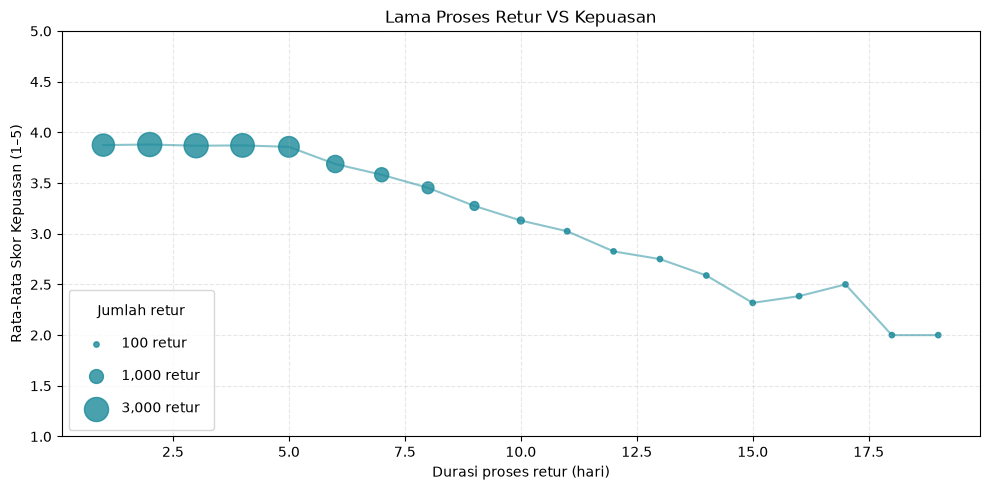

In [66]:
rt = df_return_requests[df_return_requests["resolution_status"] == "Selesai"]
puas = rt.groupby("processing_days")["satisfaction_score"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(puas.index, puas["mean"], s=ukuran(puas["size"]), color=TEAL, alpha=0.8)
ax.plot(puas.index, puas["mean"], color=TEAL, alpha=0.5)

ukuran = lambda n: np.clip(n / 10, 15, 300)
for n in [100, 1000, 3000]:
    ax.scatter([], [], s=ukuran(n), color=TEAL, alpha=0.8, label=f"{n:,} retur")
ax.legend(title="Jumlah retur", loc="lower left", labelspacing=1.3, borderpad=1)

ax.set(xlabel="Durasi proses retur (hari)", ylabel="Rata-Rata Skor Kepuasan (1–5)", ylim=(1, 5),
       title="Lama Proses Retur VS Kepuasan")
plt.grid(True, alpha=0.3, linestyle= '--')
plt.tight_layout(); plt.show()

**Insight** : Penanganan Retur

1. `3.358 klaim` gagal instalasi masih Diproses dengan usia median ±182 hari. Estimasi eksposurnya ±Rp 7,1 miliar.
2. `Skor kepuasan stabil di angka ±3,87 sampai hari ke-5` lalu turun terus hingga ±2,3 – 2,5 pada hari ke-15 dan setelahnya. Ini mendukung SLA penyelesaian retur ≤ 5 hari.
3. `Skor kepuasan kosong pada 4443 retur` dikarenakan statusnya masih Diproses atau Ditolak.

<a id="eda-12"></a>
### 12. Apakah Kehadiran Toko Fisik (DEC) Berkaitan dengan Pembelian Online?

Kota DEC didefinisikan sebagai kota domisili customer yang memiliki toko fisik Dekoruma. Jumlah order online (Mobile App dan Web) akan dibandingkan antara kota yang memiliki DEC dan kota tanpa DEC.

In [83]:
# daftar kota yang punya toko fisik (DEC)
dec_city = set(df_stores.loc[df_stores["channel_type"] == "Physical Store", "city"].dropna())

# order dengan kota domisili customer diketahui
k = df.dropna(subset=["domicile_city"]).copy()
k["online"] = k["channel_type"].isin(["Mobile App", "Web"])
k["kota_dec"] = k["domicile_city"].isin(dec_city)

porsi_online = (k.groupby("kota_dec")["online"]
                  .agg(semua_order="size", order_online="sum", porsi_online="mean")
                  .rename(index={True: "Kota ada DEC", False: "Kota tanpa DEC"})
                  .sort_values("porsi_online", ascending=False))
porsi_online["porsi_online"] = (porsi_online["porsi_online"] * 100).round(1)
display(porsi_online)

,semua_order,order_online,porsi_online
kota_dec,,,
Kota ada DEC,252751,37042,14.70
Kota tanpa DEC,55493,3843,6.90


In [88]:
jumlah_dec = df_stores[df_stores["channel_type"] == "Physical Store"].groupby("city").size()

# order online per kota DEC (dengan domisili customer diketahui)
lokasi_dec = (k[k["kota_dec"]].groupby("domicile_city")["online"]
                .agg(semua_order="size", order_online="sum", porsi_online="mean")
                .sort_values("order_online", ascending=False))
lokasi_dec.insert(0, "jumlah_toko_dec", jumlah_dec)
lokasi_dec["porsi_online"] = (lokasi_dec["porsi_online"] * 100).round(1)
lokasi_dec.index.name = "kota_dec"
display(lokasi_dec)

,jumlah_toko_dec,semua_order,order_online,porsi_online
kota_dec,,,,
Bandung,2,16778,4729,28.20
Bekasi,4,31058,4654,15.00
Kelapa Gading,7,45500,4650,10.20
Medan,3,18761,4635,24.70
Alam Sutera,8,50351,4633,9.20
Bintaro,5,35812,4611,12.90
Kemang,4,31518,4570,14.50
Surabaya,5,22973,4560,19.80


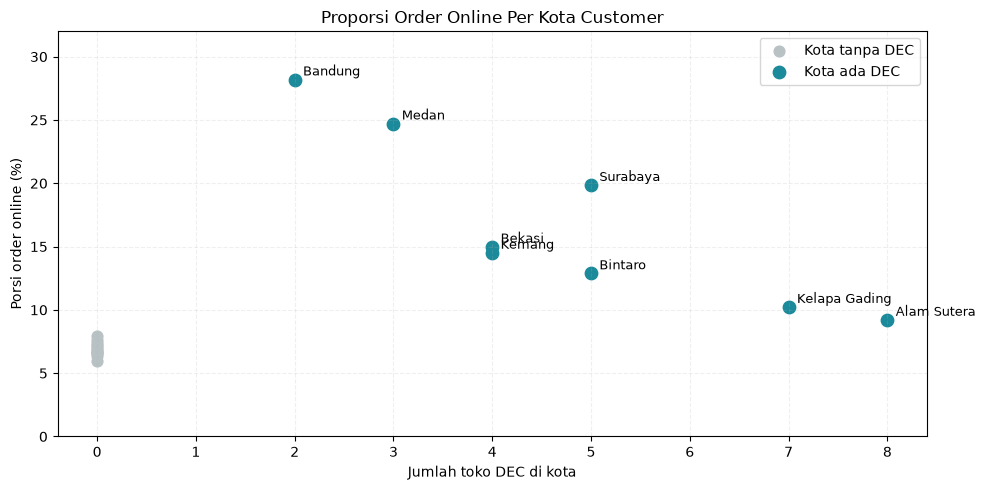

In [85]:
kota = (k.groupby("domicile_city")["online"].mean() * 100).to_frame("online_pct")
kota["n_dec"] = kota.index.map(df_stores[df_stores["channel_type"] == "Physical Store"].groupby("city").size()).fillna(0)

fig, ax = plt.subplots(figsize=(10, 5))
ada = kota["n_dec"] > 0
ax.scatter(kota.loc[~ada, "n_dec"], kota.loc[~ada, "online_pct"], s=60, color=GRY, label="Kota tanpa DEC")
ax.scatter(kota.loc[ada, "n_dec"], kota.loc[ada, "online_pct"], s=80, color=TEAL, label="Kota ada DEC")
for kt, r in kota[ada].iterrows():
    ax.annotate(kt, (r["n_dec"], r["online_pct"]), xytext=(6, 3), textcoords="offset points", fontsize=9)
ax.set(xlabel="Jumlah toko DEC di kota", ylabel="Porsi order online (%)", ylim=(0, 32),
       title="Proporsi Order Online Per Kota Customer"); ax.legend()
plt.grid(True, linestyle='--', alpha=0.2)
plt.tight_layout(); plt.show()

**Insight** : Kehadiran DEC dan Penjualan Online

1. `Kota yang memiliki DEC` mempunyai proporsi pesanan online lebih tinggi` (14,7% vs 6,9%), dan sebanyak ±90,6% order online berasal dari kota yang memiliki DEC.
2. `Efeknya jumlah DEC perkota` : Alam Sutera dengan 8 DEC hanya 9,2% online, sedangkan Bandung dengan 2 DEC mencapai 28,2%.

<a id="eda-13"></a>
### 13. Seberapa Besar Kontribusi Toko yang Tidak Tercatat dalam Atribusi?

Atribusi saat ini mencatat order online sebagai milik App/Web. Pada bagian ini mengukur jumlah order online yang didahului dengan membeli langsung di DEC.

In [91]:
srt = df.sort_values("order_date")
first_store = srt[~srt["online"]].groupby("customer_id")["order_date"].min()
on = srt[srt["online"]].copy()
on["toko_sebelumnya"] = (on["order_date"] > on["customer_id"].map(first_store)).fillna(False)

pembeli = df.groupby("customer_id").agg(pernah_online=("online", "max"), pernah_toko=("online", lambda s: (~s).any()))
pembeli_online = pembeli[pembeli["pernah_online"]]

print(f"Jumlah order online                               : {len(on):,}")
print(f"Jumlah pembeli online                             : {len(pembeli_online):,}")
print(f"Pembeli online yang juga pernah beli di DEC       : {pembeli_online['pernah_toko'].sum():,} ({pembeli_online['pernah_toko'].mean()*100:.1f}%)")
print(f"Order online yang didahului pembelian di DEC      : {on['toko_sebelumnya'].sum():,} ({on['toko_sebelumnya'].mean()*100:.1f}%)")
jeda = (on.loc[on["toko_sebelumnya"], "order_date"] - on.loc[on["toko_sebelumnya"], "customer_id"].map(first_store)).dt.days
print(f"Median jeda pembelian DEC pertama -> order online : {jeda.median():.0f} hari")
print(f"Order online tanpa acquisition_channel            : {on['acquisition_channel'].isna().sum():,} ({on['acquisition_channel'].isna().mean()*100:.1f}%)")

# kanal akuisisi untuk order online yang didahului pembelian di DEC
kanal = on.loc[on["toko_sebelumnya"], "acquisition_channel"].fillna("Tidak tercatat")
akuisisi = kanal.value_counts().to_frame("jumlah_order")
akuisisi["persen"] = (akuisisi["jumlah_order"] / akuisisi["jumlah_order"].sum() * 100).round(1)
display(akuisisi)

Jumlah order online                               : 41,759
Jumlah pembeli online                             : 33,996
Pembeli online yang juga pernah beli di DEC       : 25,573 (75.2%)
Order online yang didahului pembelian di DEC      : 22,721 (54.4%)
Median jeda pembelian DEC pertama -> order online : 73 hari
Order online tanpa acquisition_channel            : 22,053 (52.8%)


,jumlah_order,persen
acquisition_channel,,
Tidak tercatat,13786,60.70
Organic,2621,11.50
Walk-in,2500,11.00
Referral,2044,9.00
Paid Ads,1770,7.80


**Insight** : Atribusi Omnichannel

1. `75,2% pembeli online` juga pernah belanja di DEC, dan `±54% order online` didahului pembelian di DEC.
2. `Hanya ±11%` customer yang tercatat Walk-in, sedangkan ±60.7% tidak memiliki catatan kanal akuisisi sama sekali.
3. `52,8% order online tanpa acquisition_channel` : ini batas utama kualitas atribusi, sehingga kontribusi DEC hanya dapat dinyatakan **berpotensi understated**.
4. `Data hanya mencatat pembelian`, bukan kunjungan : customer yang datang ke DEC tanpa membeli lalu membeli online tidak terdeteksi.

<a id="bab-8"></a>
# 8. PENUTUP

<a id="bab-8-1"></a>
## 8.1 Kesimpulan

Berdasarkan seluruh rangkaian analisis terhadap data transaksi Dekoruma Januari–Desember 2023, diperoleh kesimpulan berikut:

1. **Kegagalan instalasi tinggi dan konsisten.** Failed rate sekitar 14,1% (28.782 dari 204.557 order yang perlu pemasangan) stabil setiap bulan.
2. **Dampak finansialnya besar.** Klaim refund gagal instalasi ±Rp 38,5 miliar (91,7% dari seluruh refund valid, dan sekitar ±5,5% dari penjualan Rp 702 miliar), dan sekitar ±Rp 18,6 miliar diantaranya ditransfer ke rekening customer.
3. **Terdapat dua supplier yang bermasalah.** UMKM Furnitur Ciputat dan Mebel Rakyat Klaten memiliki failed rate ±36% dan menyumbang sekitar 30,6% kegagalan pemasangan dari 30 supplier lainnya.
4. **Kategori, jeda, installer, sertifikasi, dan lokasi bukan penyebab.** Kegagalan pemasangan pada kategori Meja Makan hilang setelah mengontrol supplier.
5. **Kegagalan instalasi karena panel rusak (sekitar 5%) merata** di semua faktor yang tercatat, sehingga penyebabnya belum dapat diidentifikasi dari data.
6. **Penanganan retur lambat.** 3.358 klaim tertahan (median ±182 hari) dan skor kepuasan turun setelah retur diproses lebih dari 5 hari.
7. **Kontribusi DEC terhadap penjualan online berpotensi understated.** ±54% order online didahului pembelian di DEC, tetapi sebagian besar tidak tercatat kanal akuisisinya.

<a id="bab-8-2"></a>
## 8.2 Rekomendasi

Berdasarkan kesimpulan di atas, berikut rekomendasi yang dapat diimplementasikan oleh Dekoruma:

| Prioritas | Rekomendasi | Aksi | Target / indikator | PIC |
|---|---|---|---|---|
| 1 | **Perbaikan 2 supplier** | Audit kelengkapan komponen, checklist sebelum pengemasan, dan memberlakukan SLA kualitas dengan penalti | Failed rate nasional ±11% dengan estimasi ±Rp 7,6 miliar klaim terhindar | Procurement |
| 2 | **Standar packing** | Uji kemasan baru untuk barang Bulky & Oversized, foto kondisi saat serah terima | Panel rusak 5% → 3% | Operations |
| 3 | **SLA klaim retur ≤ 5 hari** | Selesaikan 3.358 klaim tertahan dan melakukan survei untuk customer yang ditolak/tertahan | Backlog 0 klaim > 30 hari | Customer Experience |
| 5 | **Perbaikan atribusi** | Mewajibkan pengisian `acquisition_channel`, memberikan tanda pada order online yang didahului pembelian / kunjungan ke DEC| Kanal akuisisi tercatat > 90% | Marketing & Data |